In [562]:
import pandas as pd
import numpy as np
import sys
import os
import matplotlib.pyplot as plt

In [563]:
d = pd.read_excel(r"E:\aug-2025\Introduction-mms\project-2\cityData\Project 2_Metro Station Survey Data.xlsx", sheet_name="Delhi ")
location = pd.read_csv(r"E:\aug-2025\Introduction-mms\project-2\cityData\DELHI_METRO_DATA.csv")

location.head()

,Station,Line,Latitude,Longitude
0,Adarsh Nagar,Yellow Line,28.714401,77.167288
1,AIIMS,Yellow Line,28.566860,77.207806
2,Akshardham,Blue Line,28.617842,77.279488
3,Anand Vihar ISBT,Blue Line branch,28.646753,77.318004
4,Arjan Garh,Yellow Line,28.480735,77.125762


Number of null values in 'Metro Station at which the survey is being conducted': 2
Metro Station at which the survey is being conducted
Kashmere Gate    468
Nehru Enclave    412
Najafgarh        412
Rithala          376
Hauz Khas        373
Nangloi          362
Jamia Millia     352
Central Sect     341
ITO              312
Karol Bagh       300
Name: count, dtype: int64


<Axes: xlabel='Metro Station at which the survey is being conducted'>

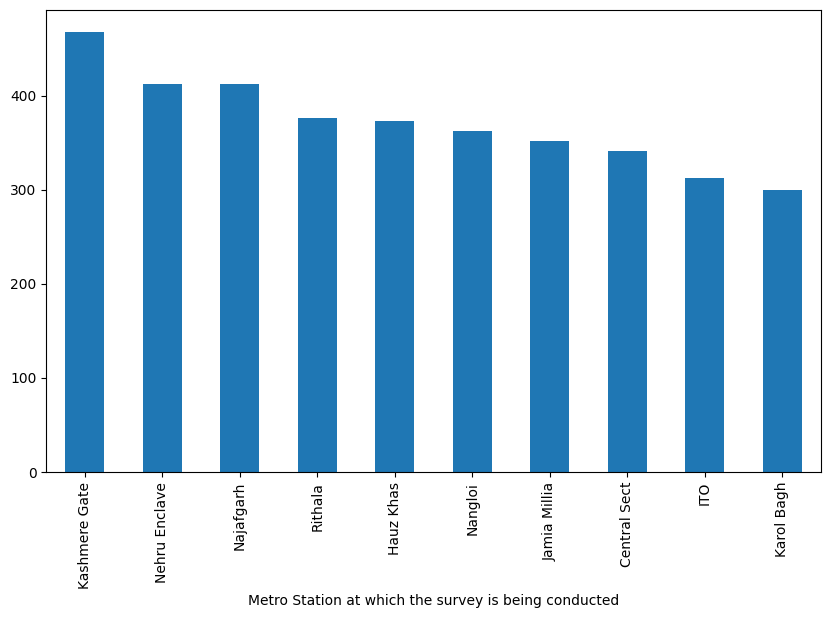

In [564]:
# Metro Station at which the survey is being conducted

column_name_metro_station = 'Metro Station at which the survey is being conducted'
# Null values in metro station
null_values_metro_station = d[column_name_metro_station].isnull().sum()
print(f"Number of null values in 'Metro Station at which the survey is being conducted': {null_values_metro_station}")

# Value counts in metro station
print(d[column_name_metro_station].value_counts())

# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_metro_station].value_counts().plot(kind='bar')

In [565]:
location.columns
# drop rows with null
d = d.dropna(subset=[column_name_metro_station])

In [ ]:
# Location within station where survey is being conducted (example – entry gate/exit gate/platform).
column_name_location_within_station = 'Location within station where survey is being conducted (example – entry gate/exit gate/platform).'

# Which is the **Origin** metro station of this trip? / Which is the **Destination** metro station of this trip?
column_name_origin_destination = 'Which is the **Origin** metro station of this trip? / Which is the **Destination** metro station of this trip?'


old_names = d[column_name_origin_destination].unique().tolist()
print(len(old_names))
new_names = location['Station'].unique().tolist()
print(len(new_names))


# Null values in origin/destination
null_values_origin_destination = d[column_name_origin_destination].isnull().sum()
print(f"Number of null values in 'Which is the **Origin** metro station of this trip? / Which is the **Destination** metro station of this trip?': {null_values_origin_destination}")

# Remove the null values
d = d[~d[column_name_origin_destination].isnull()]
print(f"Number of null values after removal: {d[column_name_origin_destination].isnull().sum()}")

# Null values in location
null_values_location = location.isnull().sum().sum()
print(f"Number of null values in location data: {null_values_location}")

# Drop Null values
location = location.dropna()
print(f"Number of null values in location data after removal: {location.isnull().sum().sum()}")

import rapidfuzz
from rapidfuzz import process, fuzz

correct_names = location['Station'].unique()
print(len(correct_names))

def correct_name(wrong):
    match, score, _ = process.extractOne(wrong, correct_names, scorer=fuzz.ratio)
    return match if score > 40 else wrong   # threshold 80% similarity

d[column_name_origin_destination] = d[column_name_origin_destination].apply(correct_name)

print(len(d[column_name_origin_destination].unique().tolist()))
d = d.merge(location, left_on=column_name_origin_destination, right_on='Station', how='left')


228
228
Number of null values in 'Which is the **Origin** metro station of this trip? / Which is the **Destination** metro station of this trip?': 0
Number of null values after removal: 0
Number of null values in location data: 14
Number of null values in location data after removal: 0
221
200


In [567]:
print(len(d['Station'].unique()))

print(d['Station'].isnull().sum())
print(len(d[column_name_origin_destination].unique().tolist()))

print(d['Longitude'].isnull().sum())
print(d['Latitude'].isnull().sum())

print(d.columns.tolist())

print(d[['Station', 'Longitude', 'Latitude']].head())

200
0
200
0
0
['Respondent ID', 'Metro Station at which the survey is being conducted', 'Location within station where survey is being conducted (example – entry gate/exit gate/platform).', 'Which is the **Origin** metro station of this trip? / Which is the **Destination** metro station of this trip?', 'Frequency of the trip', 'purpose of this trip', 'When was this trip taken', 'When do you make the return ', 'First mile connection (Leg 1)', 'First mile connection (Leg 2)', 'Primary Mode (Leg 1)', 'Primary Mode (Leg 2)', 'Last Mile connection (Leg 1)', 'Last Mile connection (Leg 2)', 'F1.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip time in minute', 'F2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - First mile connection (Leg 1) - Wait time in minute', 'F3.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip Cost (In Rupees) :', 'F4. How 

In [568]:
# Origin and Destination metro station

d['Origin Station'] = d.apply(lambda row: row[column_name_metro_station] if 'Entry Gate' in row[column_name_location_within_station] else row[column_name_origin_destination], axis=1)
d['Destination Station'] = d.apply(lambda row: row[column_name_metro_station] if 'Exit Gate' in row[column_name_location_within_station] else row[column_name_origin_destination], axis=1)



Number of null values in 'Frequency of the trip': 0
['3-5 times a week' '>5 times a week' '1-2 times a week']
Frequency of the trip
>5 times a week     1766
3-5 times a week    1366
1-2 times a week     576
Name: count, dtype: int64


<Axes: xlabel='Frequency of the trip'>

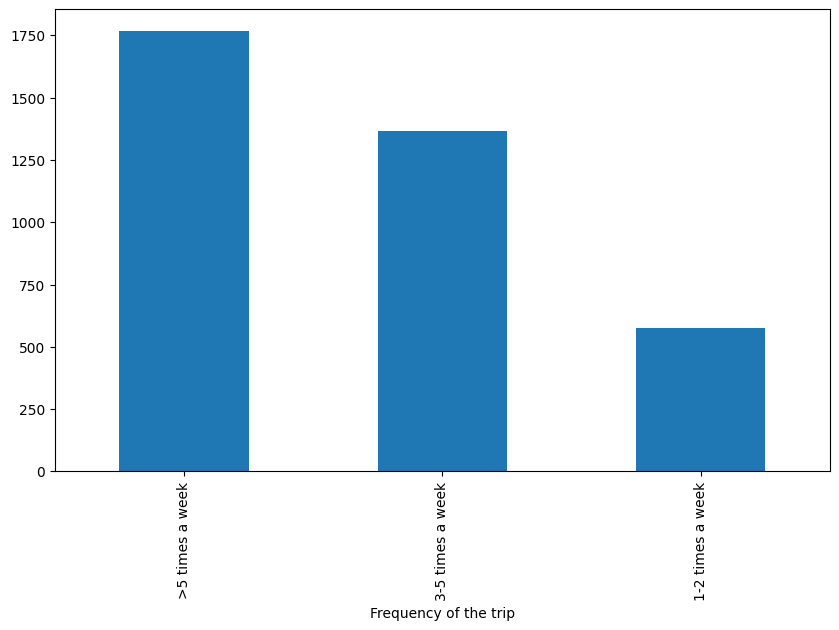

In [569]:
# Frequency of the trip
column_name_frequency_of_trip = 'Frequency of the trip'
# Null values in frequency of trip
null_values_frequency_of_trip = d[column_name_frequency_of_trip].isnull().sum()
print(f"Number of null values in 'Frequency of the trip': {null_values_frequency_of_trip}")

# unique values frequency of trip
print(d[column_name_frequency_of_trip].unique())

# value counts frequency of trip
print(d[column_name_frequency_of_trip].value_counts())

# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_frequency_of_trip].value_counts().plot(kind='bar')

Number of null values in 'Purpose of the trip': 0
['Work' 'Educational (visit School, College, etc.)'
 'Shopping (visit supermarket, mandis, shopping mall, etc.)'
 'Social (visit friend, relative, etc.)'
 'Health (visit Hospital, Clinic, etc.)'
 'Transportation Hub (visit Airport, Railway St., Bus Terminus, etc.)'
 'Recreational (visit movie theatre, shopping mall, etc.)'
 'Any other (please specify)']
purpose of this trip
Work         1853
Outing        906
Education     807
Others        142
Name: count, dtype: int64


<Axes: xlabel='purpose of this trip'>

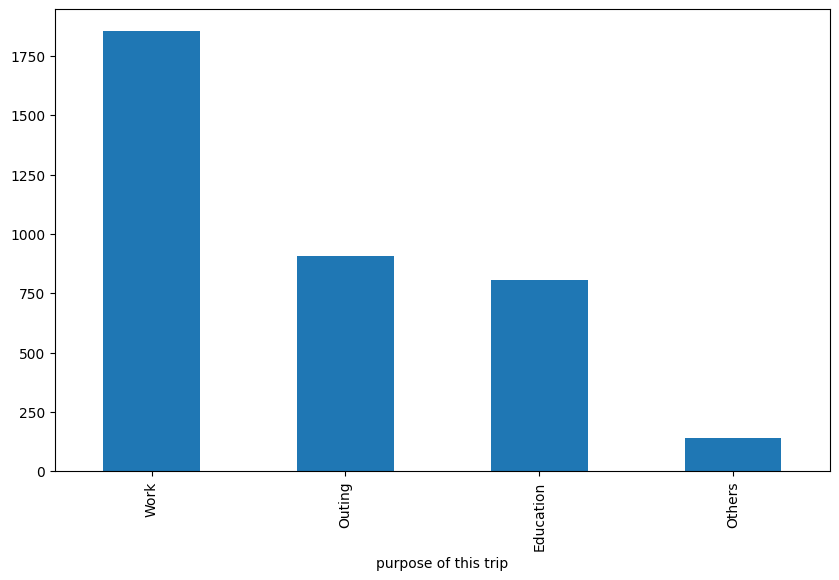

In [570]:
# purpose of this trip
column_name_purpose_of_trip = 'purpose of this trip'
# Null values in purpose of trip
null_values_purpose_of_trip = d[column_name_purpose_of_trip].isnull().sum()
print(f"Number of null values in 'Purpose of the trip': {null_values_purpose_of_trip}")

# unique values purpose of trip
print(d[column_name_purpose_of_trip].unique())

mapping = {'Educational (visit School, College, etc.)': 'Education',
           'Work': 'Work',
           'Social (visit friend, relative, etc.)': 'Outing',
           'Health (visit Hospital, Clinic, etc.)': 'Others',
           'Recreational (visit movie theatre, shopping mall, etc.)': 'Outing',
           'Shopping (visit supermarket, mandis, shopping mall, etc.)': 'Outing',
           'Transportation Hub (visit Airport, Railway St., Bus Terminus, etc.)': 'Others',
           'Any other (please specify)': 'Others'}

d[column_name_purpose_of_trip] = d[column_name_purpose_of_trip].replace(mapping)
# value counts purpose of trip
print(d[column_name_purpose_of_trip].value_counts())

# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_purpose_of_trip].value_counts().plot(kind='bar')

Number of null values in 'When was this trip taken': 0
['Evening Peak (05:00 PM – 07:59 PM)' 'Morning Peak (08:00 AM – 10:59 AM)'
 'Morning Off-Peak (11:00 AM – 04:59 PM)'
 'Early Morning (06:00 AM – 07:59 AM)'
 'Evening Off- Peak (08:00 PM – 11:30 PM)' 'One way trip']
When was this trip taken
Morning Peak (08:00 AM – 10:59 AM)         1320
Evening Peak (05:00 PM – 07:59 PM)         1248
Morning Off-Peak (11:00 AM – 04:59 PM)     1057
Early Morning (06:00 AM – 07:59 AM)          45
Evening Off- Peak (08:00 PM – 11:30 PM)      22
One way trip                                 16
Name: count, dtype: int64


<Axes: xlabel='When was this trip taken'>

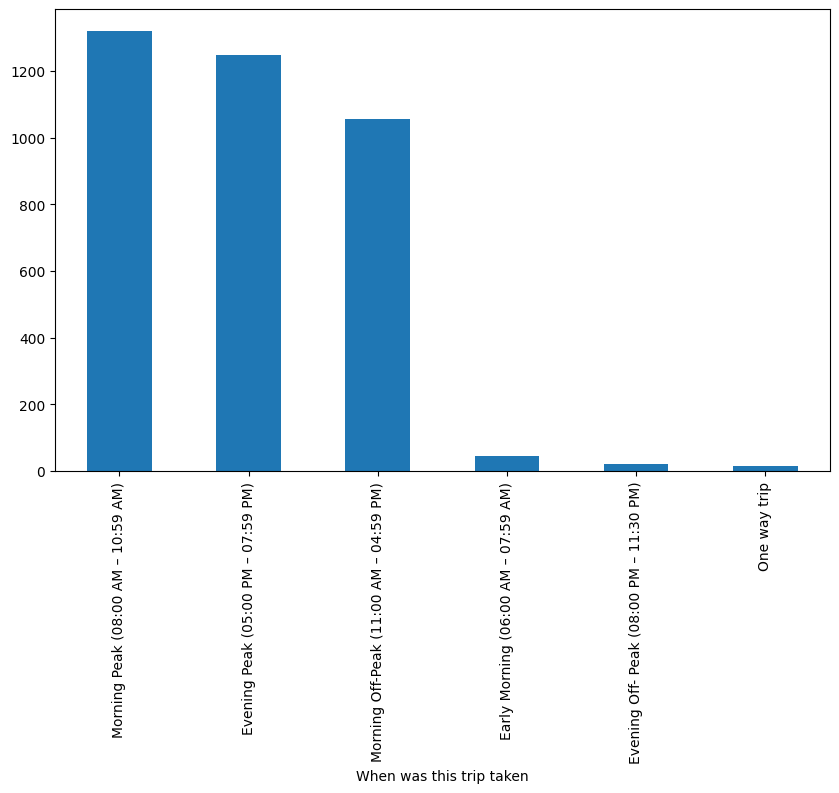

In [571]:
# When was this trip taken
column_name_when_was_trip_taken = 'When was this trip taken'
# Null values in when was trip taken
null_values_when_was_trip_taken = d[column_name_when_was_trip_taken].isnull().sum()
print(f"Number of null values in 'When was this trip taken': {null_values_when_was_trip_taken}")

# unique values when was trip taken
print(d[column_name_when_was_trip_taken].unique())
# value counts when was trip taken
print(d[column_name_when_was_trip_taken].value_counts())
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_when_was_trip_taken].value_counts().plot(kind='bar')

Number of null values in 'When do you make the return': 0
['Morning Peak (08:00 AM – 10:59 AM)' 'Evening Peak (05:00 PM – 07:59 PM)'
 'Morning Off-Peak (11:00 AM – 04:59 PM)'
 'Evening Off- Peak (08:00 PM – 11:30 PM)'
 'Early Morning (06:00 AM – 07:59 AM)' 'One way trip']
When do you make the return 
Evening Peak (05:00 PM – 07:59 PM)         1736
Morning Peak (08:00 AM – 10:59 AM)          851
Evening Off- Peak (08:00 PM – 11:30 PM)     600
Morning Off-Peak (11:00 AM – 04:59 PM)      235
Early Morning (06:00 AM – 07:59 AM)         163
One way trip                                123
Name: count, dtype: int64


<Axes: xlabel='When do you make the return '>

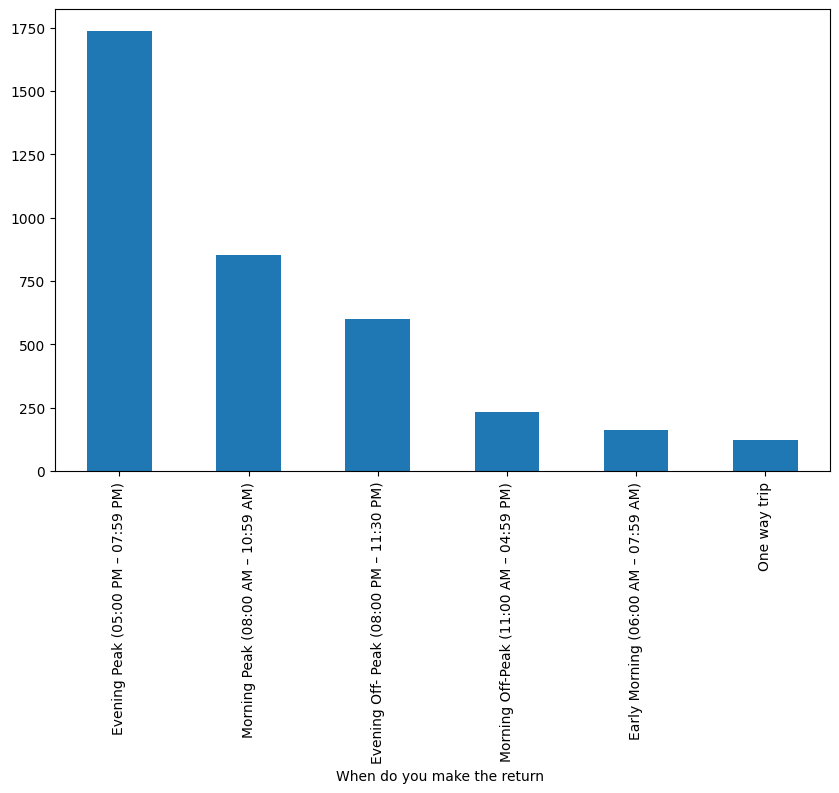

In [572]:
# When do you make the return 
column_name_when_do_you_make_return = 'When do you make the return '
# Null values in when do you make return
null_values_when_do_you_make_return = d[column_name_when_do_you_make_return].isnull().sum()
print(f"Number of null values in 'When do you make the return': {null_values_when_do_you_make_return}")

# unique values when do you make return
print(d[column_name_when_do_you_make_return].unique())
# value counts when do you make return
print(d[column_name_when_do_you_make_return].value_counts())
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_when_do_you_make_return].value_counts().plot(kind='bar')

Number of null values in 'First mile connection (Leg 1)': 0
Unique values in 'First mile connection (Leg 1)': ['Walk' 'Auto (shared)' 'E-rickshaw' 'E-auto' 'Auto (regular)'
 'Two-wheeler (self-drive)' 'Cycle' 'RTV' 'DTC BUS'
 'Somebody picks or drops me (including carpool)' 'Metro feeder bus'
 'Gramin Sewa' 'Shared taxi' 'Company transport'
 'Four-wheeler (self-drive)']
First mile connection (Leg 1)
Walk           2745
Auto            899
Two-wheeler      24
Bus              14
Cycle            12
Others           11
Car/Taxi          3
Name: count, dtype: int64


<Axes: xlabel='First mile connection (Leg 1)'>

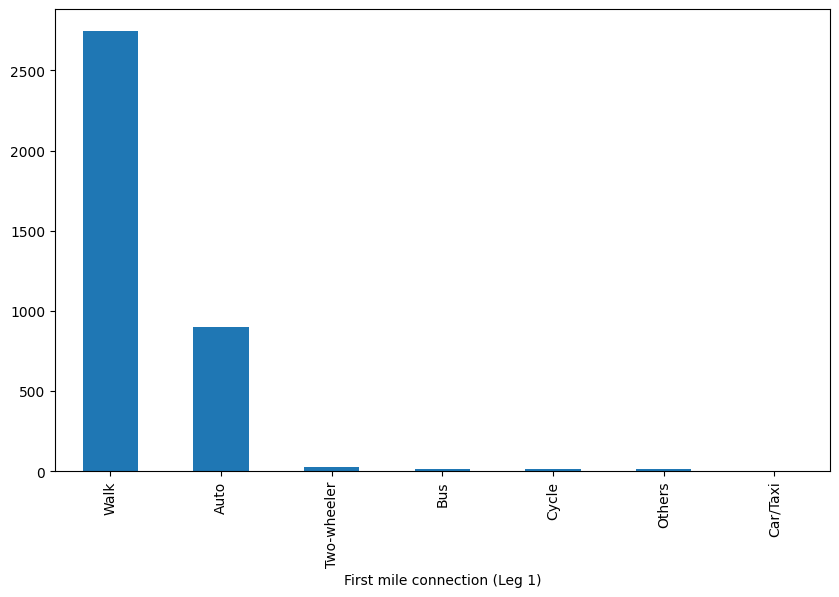

In [573]:
#First mile connection (Leg 1)

column_name_first_mile_leg_1 = 'First mile connection (Leg 1)'
# Null values in first mile leg 1
null_values = d[column_name_first_mile_leg_1].isnull().sum()
print(f"Number of null values in 'First mile connection (Leg 1)': {null_values}")

# Unique values in first mile leg 1
unique_values_leg_1 = d[column_name_first_mile_leg_1].unique()
print(f"Unique values in 'First mile connection (Leg 1)': {unique_values_leg_1}")

mapping = {
    'Auto': 'Auto',
    'Auto (shared)': 'Auto',
    'Two-wheeler (self-drive)': 'Two-wheeler',
    'Somebody picks or drops me (including carpool)': 'Others',
    'Cycle': 'Cycle',
    'Auto (Hail-Regular)': 'Auto',
    'Auto (App Based- Ola/ Uber/ Rapido)': 'Auto',
    'Public Bicycle Sharing (App Based- Yulu)': 'Cycle',
    'Two-Wheeler (App Based- Rapido)': 'Two-wheeler',
    'Four-wheeler (self-drive)': 'Car/Taxi',
    'Shared taxi': 'Car/Taxi',
    'Walk': 'Walk',
    'E-rickshaw':'Auto',
    'E-auto':'Auto',
    'Auto (regular)': 'Auto',
    'RTV':'Bus',
    'DTC BUS':'Bus',
    'Metro feeder bus':'Bus',
    'Gramin Sewa' : 'Others',
    'Company transport': 'Others',


}

d[column_name_first_mile_leg_1] = d[column_name_first_mile_leg_1].replace(mapping)

# Value counts in first mile leg 1
value_counts = d[column_name_first_mile_leg_1].value_counts()
print(value_counts)

# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_first_mile_leg_1].value_counts().plot(kind='bar')

Number of null values in 'First mile connection (Leg 2)': 2167
Number of null values in 'First mile connection (Leg 2)' after filling: 0
['Auto' 'No First mile leg 2' 'Others' 'Walk' 'Two-wheeler' 'Bus'
 'Car/Taxi' 'Cycle']
First mile connection (Leg 2)
No First mile leg 2    2167
Auto                   1088
Bus                     241
Others                  139
Car/Taxi                 33
Cycle                    15
Two-wheeler              14
Walk                     11
Name: count, dtype: int64


C:\Users\maddi\AppData\Local\Temp\ipykernel_12412\1325208809.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d[column_name_First_mile_leg_2].fillna("No First mile leg 2", inplace=True)


<Axes: xlabel='First mile connection (Leg 2)'>

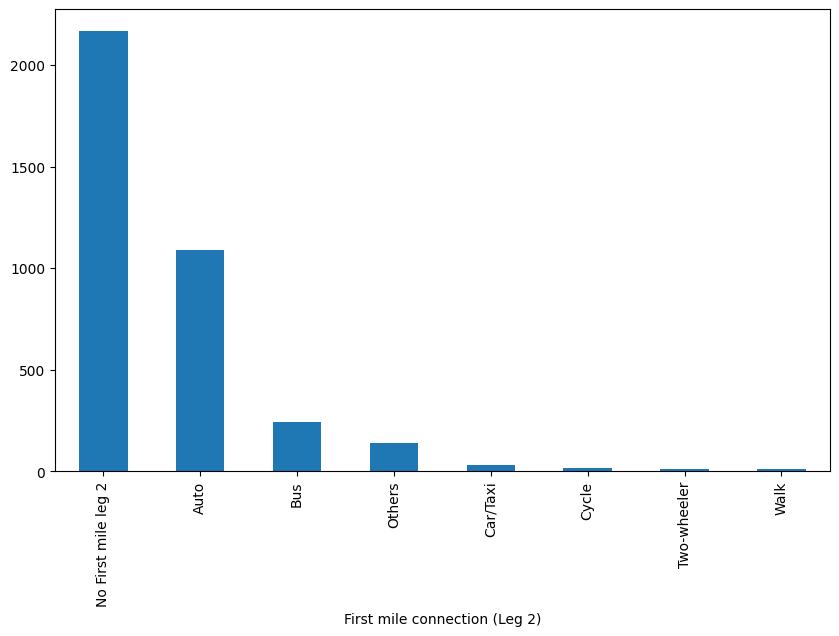

In [574]:
# First mile connection (Leg 2)

column_name_First_mile_leg_2 = 'First mile connection (Leg 2)'

# Null values in first mile leg 2
null_values_leg_2 = d[column_name_First_mile_leg_2].isnull().sum()
print(f"Number of null values in 'First mile connection (Leg 2)': {null_values_leg_2}")

# Fill Null values
d[column_name_First_mile_leg_2].fillna("No First mile leg 2", inplace=True)

null_values_leg_2_after = d[column_name_First_mile_leg_2].isnull().sum()
print(f"Number of null values in 'First mile connection (Leg 2)' after filling: {null_values_leg_2_after}")

mapping = {
    'Auto': 'Auto',
    'Auto (shared)': 'Auto',
    'Two-wheeler (self-drive)': 'Two-wheeler',
    'Somebody picks or drops me (including carpool)': 'Others',
    'Cycle': 'Cycle',
    'Auto (Hail-Regular)': 'Auto',
    'Auto (App Based- Ola/ Uber/ Rapido)': 'Auto',
    'Public Bicycle Sharing (App Based- Yulu)': 'Cycle',
    'Two-Wheeler (App Based- Rapido)': 'Two-wheeler',
    'Four-wheeler (self-drive)': 'Car/Taxi',
    'Shared taxi': 'Car/Taxi',
    'Walk': 'Walk',
    'E-rickshaw':'Auto',
    'E-auto':'Auto',
    'Auto (regular)': 'Auto',
    'RTV':'Bus',
    'DTC BUS':'Bus',
    'Metro feeder bus':'Bus',
    'Gramin Sewa' : 'Others',
    'Company transport': 'Others',
    'No First mile leg 2': 'No First mile leg 2',
    'Regular taxi': 'Car/Taxi',
    'Cycle-rickshaw': 'Cycle',
    'Any Others, Pls Specify': 'Others'
}
d[column_name_First_mile_leg_2] = d[column_name_First_mile_leg_2].replace(mapping)
print(d[column_name_First_mile_leg_2].unique())

# Value counts in first mile leg 2
value_counts_leg_2 = d[column_name_First_mile_leg_2].value_counts()
print(value_counts_leg_2)
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_First_mile_leg_2].value_counts().plot(kind='bar')

Number of null values in 'Primary Mode (Leg 1)': 0
['Metro' 'DTC BUS' 'RTV']
Primary Mode (Leg 1)
Metro    3632
Bus        76
Name: count, dtype: int64


<Axes: xlabel='Primary Mode (Leg 1)'>

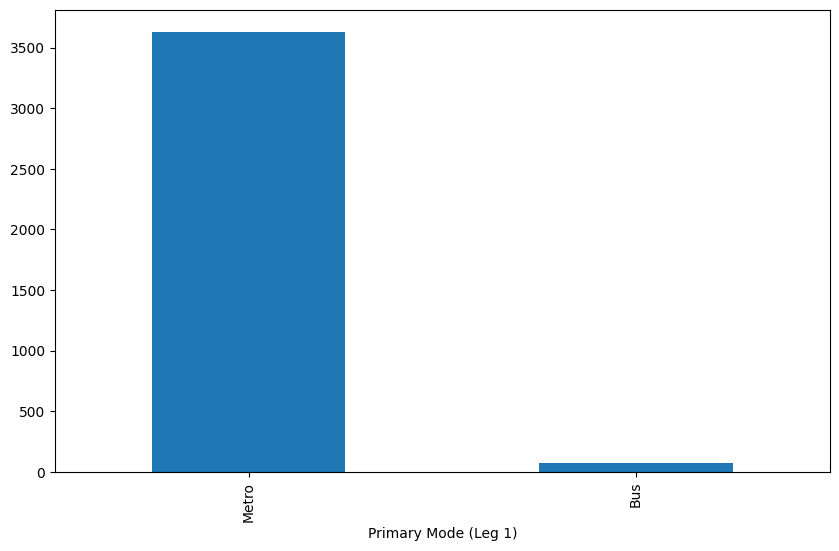

In [575]:
# Primary Mode (Leg 1)

column_name_primary_mode_leg_1 = 'Primary Mode (Leg 1)'

# Null values in primary mode
null_values_primary_mode = d[column_name_primary_mode_leg_1].isnull().sum()
print(f"Number of null values in 'Primary Mode (Leg 1)': {null_values_primary_mode}")

# Unique values in primary mode
print(d[column_name_primary_mode_leg_1].unique())

mapping = {
    'Metro' : 'Metro',
    'DTC BUS' : 'Bus',
    'RTV' : 'Bus',
    'Train' : 'Train',
    'Any Others, Please Specify' : 'Others',
    'Company Transport' : 'Others'
}
d[column_name_primary_mode_leg_1] = d[column_name_primary_mode_leg_1].replace(mapping)

# Value counts in primary mode
value_counts_primary_mode = d[column_name_primary_mode_leg_1].value_counts()
print(value_counts_primary_mode)
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_primary_mode_leg_1].value_counts().plot(kind='bar')

Number of null values in 'Primary Mode (Leg 2)': 3523
['No Primary mode leg 2' 'Metro' 'RTV' 'DTC BUS'
 'Somebody picks or drops me (including carpool)' 'Metro feeder bus']
Primary Mode (Leg 2)
No Primary mode leg 2    3523
Metro                     101
Bus                        83
Others                      1
Name: count, dtype: int64


C:\Users\maddi\AppData\Local\Temp\ipykernel_12412\3215895251.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d[column_name_primary_mode_leg_2].fillna("No Primary mode leg 2", inplace=True)


<Axes: xlabel='Primary Mode (Leg 2)'>

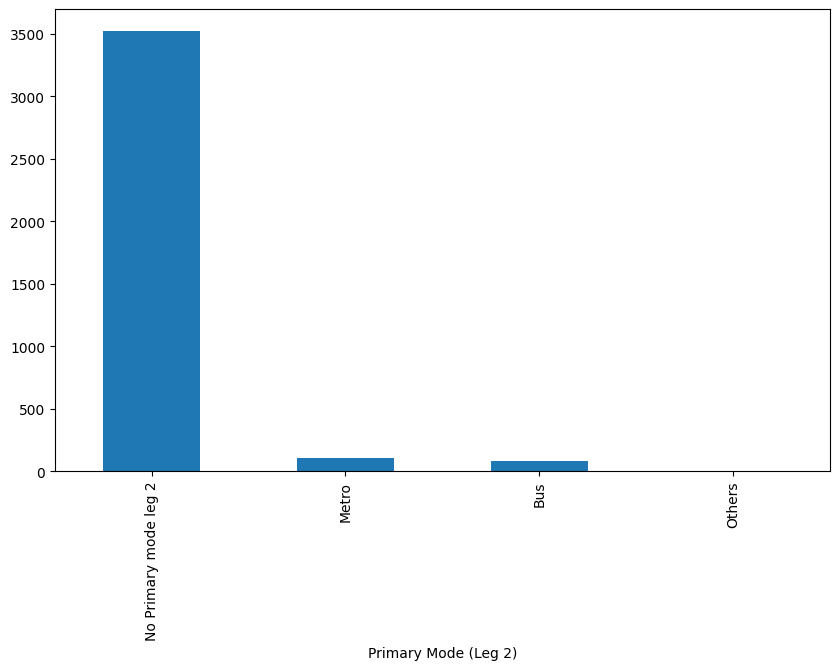

In [576]:
# Primary Mode (Leg 2)
column_name_primary_mode_leg_2 = 'Primary Mode (Leg 2)'

# Null values in primary mode leg 2
null_values_primary_mode_leg_2 = d[column_name_primary_mode_leg_2].isnull().sum()
print(f"Number of null values in 'Primary Mode (Leg 2)': {null_values_primary_mode_leg_2}")


# Replace null values with "No Primary mode leg 2"
d[column_name_primary_mode_leg_2].fillna("No Primary mode leg 2", inplace=True)

# Unique values in primary mode leg 2
print(d[column_name_primary_mode_leg_2].unique())

mapping = {
    'No Primary mode leg 2' : 'No Primary mode leg 2',
    'Metro' : 'Metro',
    'Metro feeder bus' : 'Bus',
    'RTV' : 'Bus',
    'Train' : 'Train',
    'Metro Feeder Bus' : 'Others',
    'Somebody picks or drops me (including carpool)' : 'Others',
    'DTC BUS' : 'Bus',

}
d[column_name_primary_mode_leg_2] = d[column_name_primary_mode_leg_2].replace(mapping)

# Value counts in primary mode leg 2
value_counts_primary_mode_leg_2 = d[column_name_primary_mode_leg_2].value_counts()
print(value_counts_primary_mode_leg_2)
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_primary_mode_leg_2].value_counts().plot(kind='bar')

Number of null values in 'Last Mile connection (Leg 1)': 0
['Walk' 'E-rickshaw' 'Auto (shared)' 'Auto (regular)' 'E-auto' 'Cycle'
 'DTC BUS' 'Metro feeder bus' 'RTV' 'Company transport' 'Cycle-rickshaw'
 'Shared taxi' 'Gramin Sewa' 'Two-wheeler (self-drive)'
 'Somebody picks or drops me (including carpool)' 'Regular taxi']
Last Mile connection (Leg 1)
Walk           2680
Auto            927
Bus              48
Car/Taxi         18
Others           17
Cycle            12
Two-wheeler       6
Name: count, dtype: int64


<Axes: xlabel='Last Mile connection (Leg 1)'>

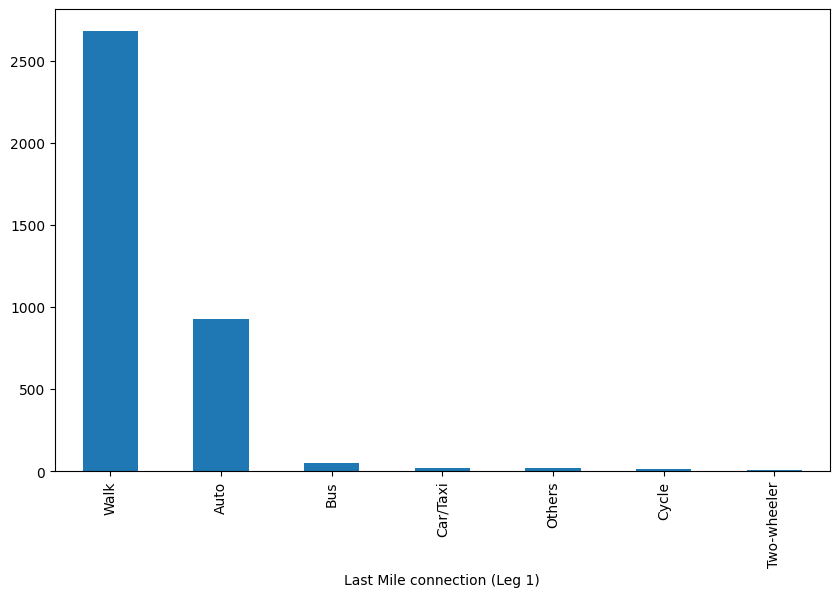

In [577]:
# Last Mile connection (Leg 1)
column_name_last_mile_leg_1 = 'Last Mile connection (Leg 1)'
# Null values in last mile leg 1
null_values_last_mile_leg_1 = d[column_name_last_mile_leg_1].isnull().sum()
print(f"Number of null values in 'Last Mile connection (Leg 1)': {null_values_last_mile_leg_1}")

# Unique values in last mile leg 1
print(d[column_name_last_mile_leg_1].unique())

mapping = {
    'Auto': 'Auto',
    'Auto (shared)': 'Auto',
    'Two-wheeler (self-drive)': 'Two-wheeler',
    'Somebody picks or drops me (including carpool)': 'Others',
    'Cycle': 'Cycle',
    'Auto (Hail-Regular)': 'Auto',
    'Auto (App Based- Ola/ Uber/ Rapido)': 'Auto',
    'Public Bicycle Sharing (App Based- Yulu)': 'Cycle',
    'Two-Wheeler (App Based- Rapido)': 'Two-wheeler',
    'Four-wheeler (self-drive)': 'Car/Taxi',
    'Shared taxi': 'Car/Taxi',
    'Walk': 'Walk',
    'E-rickshaw':'Auto',
    'E-auto':'Auto',
    'Auto (regular)': 'Auto',
    'RTV':'Bus',
    'DTC BUS':'Bus',
    'Metro feeder bus':'Bus',
    'Gramin Sewa' : 'Others',
    'Company transport': 'Others',
    'No First mile leg 2': 'No First mile leg 2',
    'Regular taxi': 'Car/Taxi',
    'Cycle-rickshaw': 'Cycle',
    'Any Others, Pls Specify': 'Others'
}

d[column_name_last_mile_leg_1] = d[column_name_last_mile_leg_1].replace(mapping)

# Value counts in last mile leg 1
value_counts_last_mile_leg_1 = d[column_name_last_mile_leg_1].value_counts()
print(value_counts_last_mile_leg_1)
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_last_mile_leg_1].value_counts().plot(kind='bar')

Number of null values in 'Last Mile connection (Leg 2)': 2960
['No Last mile leg 2' 'E-rickshaw' 'Walk' 'Auto (regular)' 'E-auto'
 'Suburban train' 'DTC BUS' 'Cycle' 'RTV' 'Regular taxi' 'Gramin Sewa'
 'Auto (shared)' 'Shared taxi'
 'Somebody picks or drops me (including carpool)' 'Company transport'
 'Cycle-rickshaw' 'Two-wheeler (self-drive)']
Last Mile connection (Leg 2)
No Last mile leg 2    2960
Walk                   307
Auto                   291
Bus                     78
Others                  44
Car/Taxi                12
Cycle                    8
Suburban train           5
Two-wheeler              3
Name: count, dtype: int64


C:\Users\maddi\AppData\Local\Temp\ipykernel_12412\2745994919.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d[column_name_last_mile_leg_2].fillna("No Last mile leg 2", inplace=True)


<Axes: xlabel='Last Mile connection (Leg 2)'>

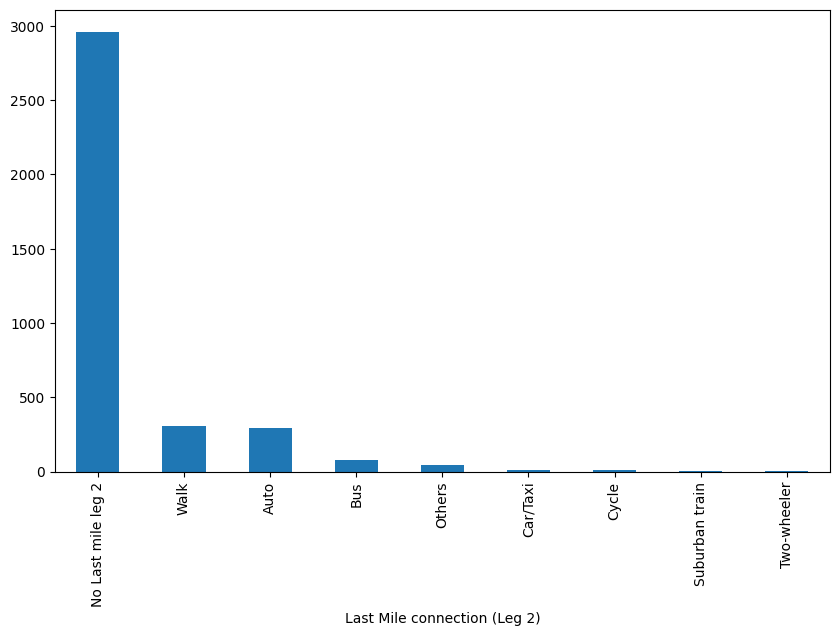

In [578]:
# Last Mile connection (Leg 2)
column_name_last_mile_leg_2 = 'Last Mile connection (Leg 2)'
# Null values in last mile leg 2
null_values_last_mile_leg_2 = d[column_name_last_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Last Mile connection (Leg 2)': {null_values_last_mile_leg_2}")

# Fill Null values
d[column_name_last_mile_leg_2].fillna("No Last mile leg 2", inplace=True)

# Unique values in last mile leg 2
print(d[column_name_last_mile_leg_2].unique())

mapping = {
    'Auto': 'Auto',
    'Auto (shared)': 'Auto',
    'Two-wheeler (self-drive)': 'Two-wheeler',
    'Somebody picks or drops me (including carpool)': 'Others',
    'Cycle': 'Cycle',
    'Auto (Hail-Regular)': 'Auto',
    'Auto (App Based- Ola/ Uber/ Rapido)': 'Auto',
    'Public Bicycle Sharing (App Based- Yulu)': 'Cycle',
    'Two-Wheeler (App Based- Rapido)': 'Two-wheeler',
    'Four-wheeler (self-drive)': 'Car/Taxi',
    'Shared taxi': 'Car/Taxi',
    'Walk': 'Walk',
    'E-rickshaw':'Auto',
    'E-auto':'Auto',
    'Auto (regular)': 'Auto',
    'RTV':'Bus',
    'DTC BUS':'Bus',
    'Metro feeder bus':'Bus',
    'Gramin Sewa' : 'Others',
    'Company transport': 'Others',
    'No First mile leg 2': 'No First mile leg 2',
    'Regular taxi': 'Car/Taxi',
    'Cycle-rickshaw': 'Cycle',
    'Any Others, Pls Specify': 'Others'
}
d[column_name_last_mile_leg_2] = d[column_name_last_mile_leg_2].replace(mapping)
# Value counts in last mile leg 2
value_counts_last_mile_leg_2 = d[column_name_last_mile_leg_2].value_counts()
print(value_counts_last_mile_leg_2)
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_last_mile_leg_2].value_counts().plot(kind='bar')

Number of null values in 'How do you usually pay for your Metro journey?': 0
10. How do you usually pay  for your Metro journey?
Smart  Card           3321
Tokens                 346
QR based ticketing      22
Tourist Card            19
Name: count, dtype: int64


<Axes: xlabel='10. How do you usually pay  for your Metro journey?'>

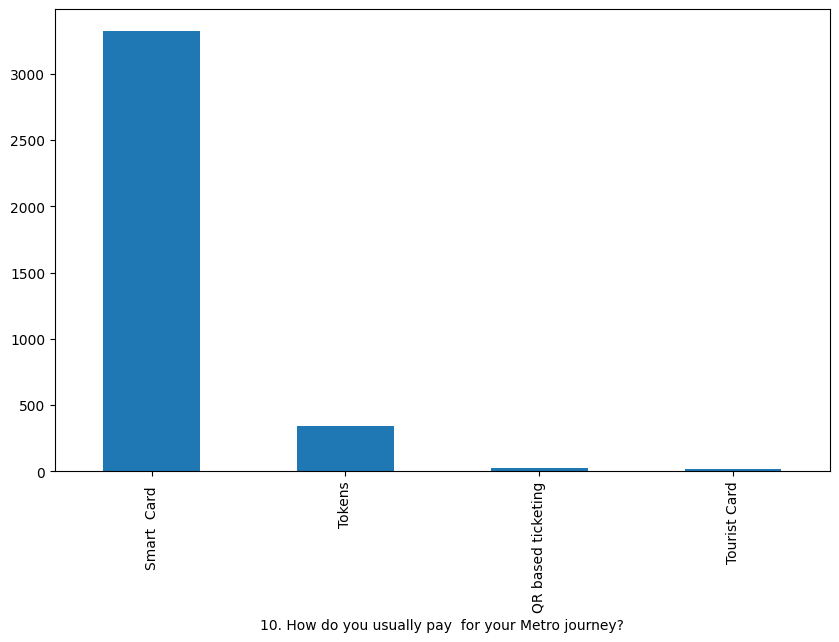

In [579]:
# Q10. How do you usually pay  for your Metro journey?
column_name_payment_method = '10. How do you usually pay  for your Metro journey?'
# Null values in payment method
null_values_payment_method = d[column_name_payment_method].isnull().sum()
print(f"Number of null values in 'How do you usually pay for your Metro journey?': {null_values_payment_method}")

mapping = {
    'Smart Card': 'Smart Card',
    'Token': 'Token',
    'Tourist Card 1': 'Tourist Card',
    'Tourist Card 3': 'Tourist Card'
}
d[column_name_payment_method] = d[column_name_payment_method].replace(mapping)

value_counts_payment_method = d[column_name_payment_method].value_counts()
print(value_counts_payment_method)

# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_payment_method].value_counts().plot(kind='bar')

Number of null values in 'Gender': 0
Gender
Female    1902
Male      1805
Others       1
Name: count, dtype: int64


<Axes: xlabel='Gender'>

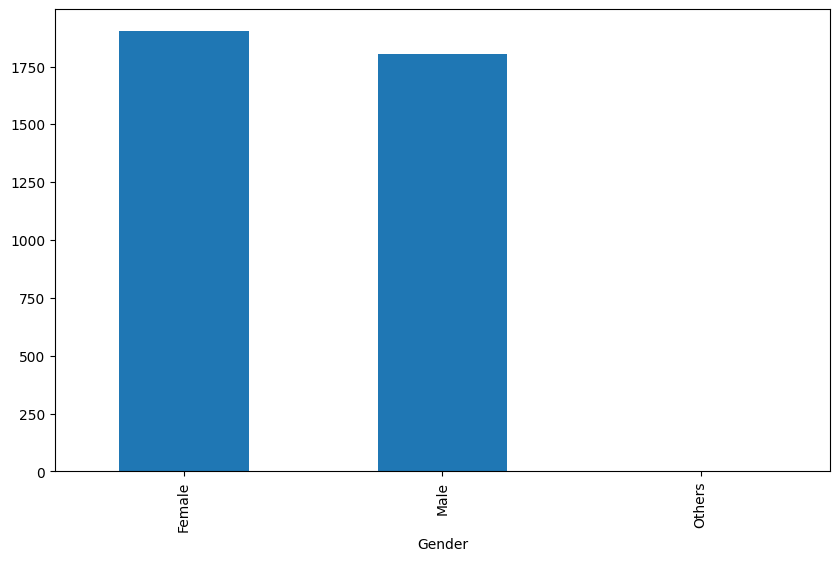

In [580]:
# Gender
column_name_gender = 'Gender'
# Null values in gender
null_values_gender = d[column_name_gender].isnull().sum()
print(f"Number of null values in 'Gender': {null_values_gender}")

# Value counts
value_counts_gender = d[column_name_gender].value_counts()
print(value_counts_gender)
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_gender].value_counts().plot(kind='bar')

Number of null values in 'Age': 0
['36 - 50\xa0' '19 - 25\xa0' '26 - 35\xa0' 'Less than 18\xa0' '51-60\xa0'
 '60+\xa0' 'Refused\xa0']
Age
19 - 25            1607
26 - 35            1384
36 - 50             555
Greater than 50      82
Less than 18         80
Name: count, dtype: int64


<Axes: xlabel='Age'>

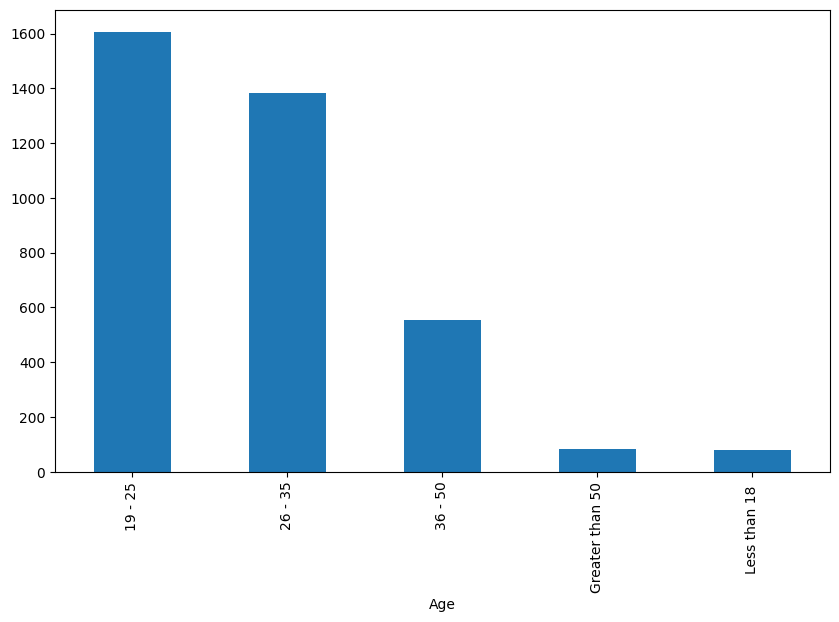

In [581]:
# Age
column_name_age = 'Age'
# Null values in age
null_values_age = d[column_name_age].isnull().sum()
print(f"Number of null values in 'Age': {null_values_age}")
# UNIQUE VALUES
print(d[column_name_age].unique())

mapping = {
    '19 - 25\xa0':'19 - 25',
    '26 - 35\xa0':'26 - 35',
    '36 - 50\xa0':'36 - 50',
    "Refused\xa0":'26 - 35',
    'Less Than 18\xa0':'Less Than 18',
    '51-60\xa0':'Greater than 50',
    '60+\xa0':'Greater than 50',
}
d[column_name_age] = d[column_name_age].replace(mapping)

# VALUE COUNTS
value_counts_age = d[column_name_age].value_counts()
print(value_counts_age)

# GRAPHICAL REPRESENTATION
plt.figure(figsize=(10,6))
d[column_name_age].value_counts().plot(kind='bar')

Number of null values in 'Educational qualification?': 0
['Some college credit, no degree'
 'High school graduate, diploma, or the equivalent (12th pass)'
 'Bachelor’s degree' 'Some high school, no diploma (10th pass)'
 'Master’s degree' 'Trade/technical/vocational training'
 'Professional degree' 'Doctorate degree' 'Up to 8th grade'
 'No schooling completed']
Educational qualification?
12th Pass        1457
Degree Holder    1272
Below 12th        614
Post Graduate     365
Name: count, dtype: int64


<Axes: xlabel='Educational qualification?'>

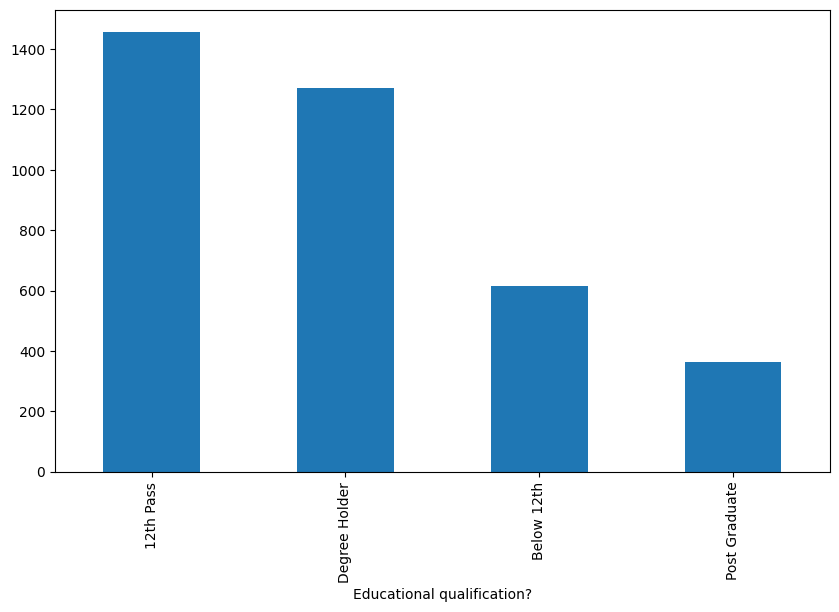

In [582]:
# Educational qualification?
column_name_education = 'Educational qualification?'
# Null values in educational qualification
null_values_education = d[column_name_education].isnull().sum()
print(f"Number of null values in 'Educational qualification?': {null_values_education}")

# UNIQUE VALUES
print(d[column_name_education].unique())

mapping = {
    
    'Some college credit, no degree' : '12th Pass',
    'Professional Degree' : 'Degree Holder',    
    'High school graduate, diploma, or the equivalent (12th pass)' : '12th Pass',
    'Trade/Technical/Vocational Training' : '12th Pass',
    'Up To 8th Grade' : 'Below 12th',
    'Masters Degree' : 'Post Graduate',
    'Doctorate degree' : 'Post Graduate',
    'Some high school, no diploma (10th pass)' : 'Below 12th',
    'No schooling completed' : 'Below 12th',
    'Bachelor’s degree' : 'Degree Holder',
    'Master’s degree' : 'Post Graduate',
    'Trade/technical/vocational training' : 'Post Graduate',
    'Professional degree' : 'Degree Holder',
    'Up to 8th grade': 'Below 12th',

}

d[column_name_education] = d[column_name_education].replace(mapping)

# VALUE COUNTS
value_counts_education = d[column_name_education].value_counts()
print(value_counts_education)

# GRAPHICAL REPRESENTATION
plt.figure(figsize=(10,6))
d[column_name_education].value_counts().plot(kind='bar')


Number of null values in 'Occupation': 0
['Employed\xa0\xa0' 'Daily wage worker\xa0' 'A student\xa0'
 'Other (Specify)\xa0' 'Self-employed\xa0' 'A homemaker\xa0'
 'Out of work but not currently looking for work\xa0'
 'Out of work and looking for work\xa0' 'Unable to work\xa0' 'Retired\xa0']
Occupation
Employed             1970
Student               980
Self-Employed         267
Homemaker             251
Unemployed            127
Daily Wage Worker     110
Retired                 3
Name: count, dtype: int64


<Axes: xlabel='Occupation'>

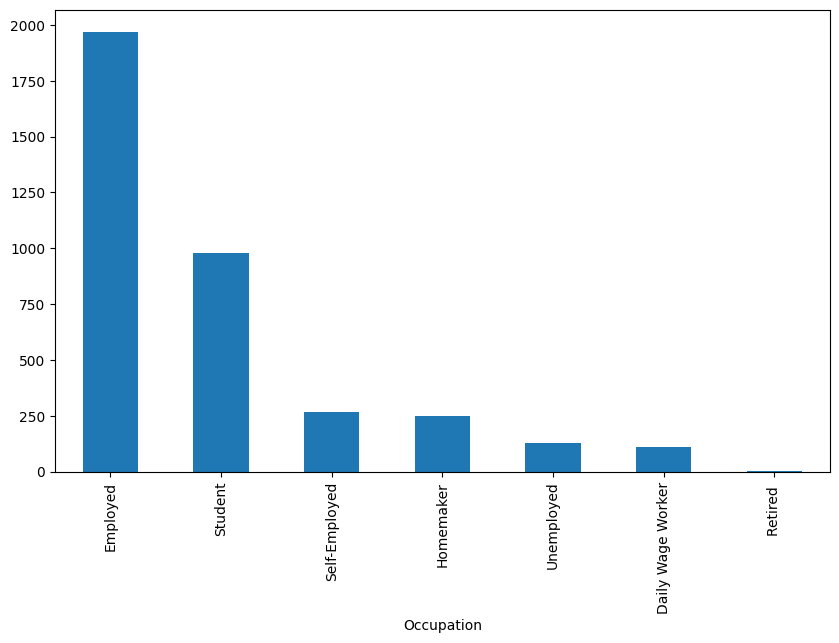

In [583]:
# Occupation

column_name_occupation = 'Occupation'
# Null values in occupation
null_values_occupation = d[column_name_occupation].isnull().sum()
print(f"Number of null values in 'Occupation': {null_values_occupation}")
# UNIQUE VALUES
print(d[column_name_occupation].unique())

mapping = {'A student\xa0' : 'Student', 
           'Employed\xa0\xa0' : 'Employed', 
           'Self-employed\xa0' : 'Self-Employed', 
           'A homemaker\xa0' : 'Homemaker',
             'Awaiting Job' : 'Unemployed',
           'Unemployed' : 'Unemployed', 
           'Daily wage worker\xa0' : 'Daily Wage Worker', 
           'Retired' : 'Retired', 
           'Unable to work\xa0' : 'Unemployed',
           'Other (Specify)\xa0': 'Unemployed',
           'Out of work but not currently looking for work\xa0': 'Unemployed',
           'Out of work and looking for work\xa0': 'Unemployed',}
d[column_name_occupation] = d[column_name_occupation].replace(mapping)

# VALUE COUNTS
value_counts_occupation = d[column_name_occupation].value_counts()
print(value_counts_occupation)
# GRAPHICAL REPRESENTATION
plt.figure(figsize=(10,6))
d[column_name_occupation].value_counts().plot(kind='bar')

Number of null values in 'Monthly household income': 0
count               3708
unique                 9
top       20,001-40,000 
freq                1424
Name: Monthly household income, dtype: object
['10,001-20,000\xa0' '20,001-40,000\xa0' '40,001-60,000\xa0' 'Refused\xa0'
 '60,001-80,000\xa0' 'Above 1,00,000\xa0' '<5k\xa0' '5,001 -10,000\xa0'
 '80,001 – 1,00,000\xa0']
Monthly household income
20,001-40,000    1793
10,001-20,000    1052
40,001-60,000     644
Above 60,000      136
5,001-10,000       81
<5k                 2
Name: count, dtype: int64


<Axes: xlabel='Monthly household income'>

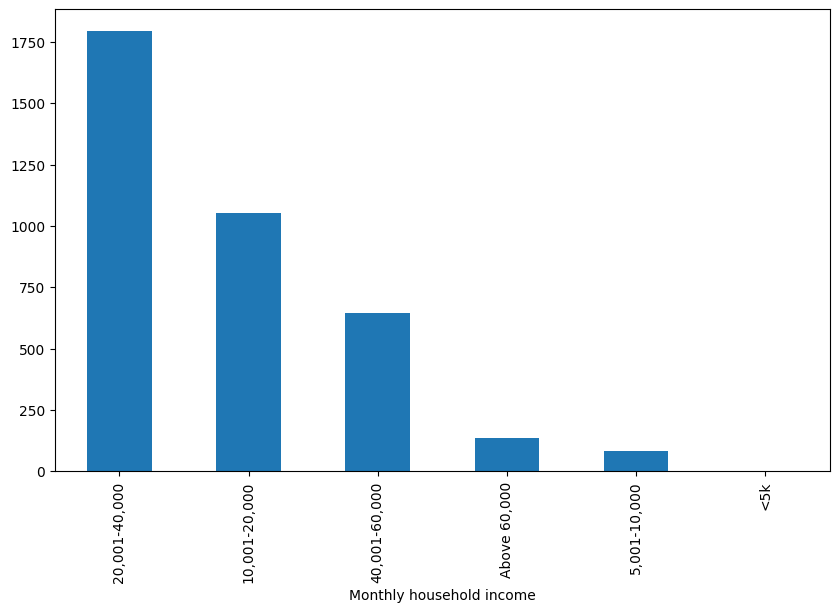

In [584]:
# Monthly household income
column_name_monthly_income = 'Monthly household income'
# Null values in monthly household income
null_values_monthly_income = d[column_name_monthly_income].isnull().sum()
print(f"Number of null values in 'Monthly household income': {null_values_monthly_income}")

print(d[column_name_monthly_income].describe())
# UNIQUE VALUES
print(d[column_name_monthly_income].unique())

mapping = {
    '5,001 -10,000\xa0': '5,001-10,000',
    '10,001-20,000\xa0': '10,001-20,000',
    '20,001-40,000\xa0': '20,001-40,000',
    '40,001-60,000\xa0': '40,001-60,000',
    '60,001-80,000\xa0': 'Above 60,000',
    '80,001 - 1,00,000\xa0': 'Above 60,000',
    'Above 1,00,000\xa0': 'Above 60,000',
    'Refused\xa0': '20,001-40,000',
    '<5k\xa0': '<5k',
    '80,001 – 1,00,000\xa0': 'Above 60,000',
}

d[column_name_monthly_income] = d[column_name_monthly_income].replace(mapping)

# VALUE COUNTS
value_counts_monthly_income = d[column_name_monthly_income].value_counts()
print(value_counts_monthly_income)
# GRAPHICAL REPRESENTATION
plt.figure(figsize=(10,6))
d[column_name_monthly_income].value_counts().plot(kind='bar')



In [585]:
# Household members

column_name_household_members = 'Household members'
# Null values in household members
null_values_household_members = d[column_name_household_members].isnull().sum()
print(f"Number of null values in 'Household members': {null_values_household_members}")

unique_values_household_members = d[column_name_household_members].unique()
print(f"Unique values in 'Household members': {unique_values_household_members}")



Number of null values in 'Household members': 0
Unique values in 'Household members': [ 5.  4.  6.  3.  7.  8. 10.  9. 11.  2. 15.  1. 20. 13.]


Number of null values in 'Number of vehicles in the household - 2W:': 0
[ 1.  0.  2.  3.  8. 11.  4. 10. 20. 13.  5. 66.]
Number of vehicles in the household - 2W:
One                 2576
Zero                 864
Two                  241
Greater than Two      24
11.0                   2
5.0                    1
Name: count, dtype: int64


<Axes: xlabel='Number of vehicles in the household - 2W:'>

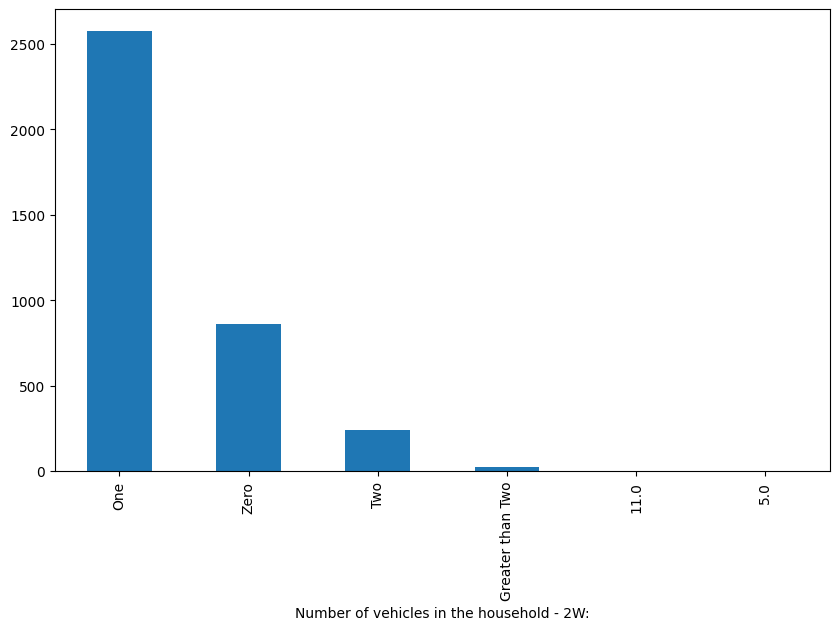

In [586]:
# Number of vehicles in the household - 2W:
column_name_vehicles_2w = 'Number of vehicles in the household - 2W:'
# Null values in 2W vehicles
null_values_vehicles_2w = d[column_name_vehicles_2w].isnull().sum()
print(f"Number of null values in 'Number of vehicles in the household - 2W:': {null_values_vehicles_2w}")

print(d[column_name_vehicles_2w].unique())

mapping = {
    0. : 'Zero'
    , 1. : 'One'
    , 2. : 'Two'
    , 10. : 'Greater than Two'
    , 55. : 'Greater than Two'
    , 13. : 'Greater than Two'
    , 4. : 'Greater than Two',
     3. : 'Greater than Two',
    8. : 'Greater than Two',
    20. : 'Greater than Two',
    66. : 'Greater than Two',

}
d[column_name_vehicles_2w] = d[column_name_vehicles_2w].replace(mapping)


value_counts_vehicles_2w = d[column_name_vehicles_2w].value_counts()
print(value_counts_vehicles_2w)
# GRAPHICAL REPRESENTATION
plt.figure(figsize=(10,6))
d[column_name_vehicles_2w].value_counts().plot(kind='bar')



Number of null values in 'Number of vehicles in the household - 4W': 0
[ 0.  1.  8.  2.  9.  3. 10.  4.]
Number of vehicles in the household - 4W
Zero                3140
One                  538
Two                   20
Greater than Two       9
4.0                    1
Name: count, dtype: int64


<Axes: xlabel='Number of vehicles in the household - 4W'>

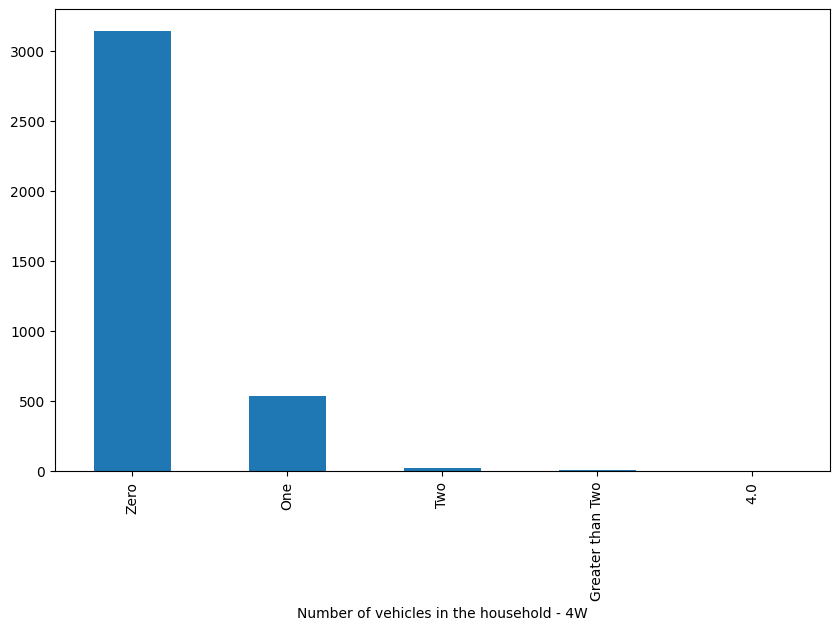

In [587]:
# Number of vehicles in the household - 4W
column_name_vehicles_4w = 'Number of vehicles in the household - 4W'
# Null values in 4W vehicles
null_values_vehicles_4w = d[column_name_vehicles_4w].isnull().sum()
print(f"Number of null values in 'Number of vehicles in the household - 4W': {null_values_vehicles_4w}")
print(d[column_name_vehicles_4w].unique())

mapping = {
    0 : 'Zero'
    , 1 : 'One'
    , 2 : 'Two'
    , 8 : 'Greater than Two'
    , 3 : 'Greater than Two'
    , 10. : 'Greater than Two'
    , 9. : 'Greater than Two'
}

d[column_name_vehicles_4w] = d[column_name_vehicles_4w].replace(mapping)

# VALUE COUNTS
value_counts_vehicles_4w = d[column_name_vehicles_4w].value_counts()
print(value_counts_vehicles_4w)
# GRAPHICAL REPRESENTATION
plt.figure(figsize=(10,6))
d[column_name_vehicles_4w].value_counts().plot(kind='bar')



Number of null values in 'Number of vehicles in the household - Cycle': 16
Number of vehicles in the household - Cycle
Yes    3533
No      175
Name: count, dtype: int64


C:\Users\maddi\AppData\Local\Temp\ipykernel_12412\852136427.py:22: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d[column_name_vehicles_cycle].fillna('Yes', inplace=True)


<Axes: xlabel='Number of vehicles in the household - Cycle'>

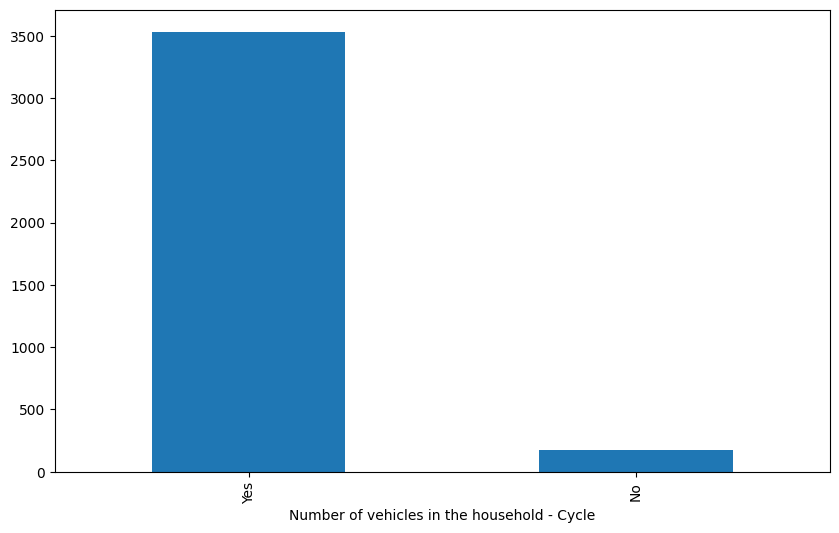

In [588]:
# Number of vehicles in the household - Cycle
column_name_vehicles_cycle = 'Number of vehicles in the household - Cycle'
# Null values in cycle vehicles
null_values_vehicles_cycle = d[column_name_vehicles_cycle].isnull().sum()
print(f"Number of null values in 'Number of vehicles in the household - Cycle': {null_values_vehicles_cycle}")

mapping = {
    0 : 'Zero'
    , 1 : 'One'
    , 2 : 'Two'
    , 3 : 'Three'
    , 8 : 'Greater than Three'
    , 4 : 'Greater than Three'
    , 31 : 'Greater than Three'
    , 5 : 'Greater than Three'
    , 6 : 'Greater than Three'
}

d[column_name_vehicles_cycle] = d[column_name_vehicles_cycle].replace(mapping)

# Fill Null values with majority value  
d[column_name_vehicles_cycle].fillna('Yes', inplace=True)

value_counts_vehicles_cycle = d[column_name_vehicles_cycle].value_counts()
print(value_counts_vehicles_cycle)
# GRAPHICAL REPRESENTATION
plt.figure(figsize=(10,6))
d[column_name_vehicles_cycle].value_counts().plot(kind='bar')




In [589]:
# Is there a vehicle belonging to you/your family that you could have used to make this trip?

column_name_vehicle_used = 'Is there a vehicle belonging to you/your family that you could have used to make this trip?'
# Null values in vehicle used
null_values_vehicle_used = d[column_name_vehicle_used].isnull().sum()
print(f"Number of null values in 'Is there a vehicle belonging to you/your family that you could have used to make this trip?': {null_values_vehicle_used}")

value_counts_vehicle_used = d[column_name_vehicle_used].value_counts()
print(value_counts_vehicle_used)

Number of null values in 'Is there a vehicle belonging to you/your family that you could have used to make this trip?': 0
Is there a vehicle belonging to you/your family that you could have used to make this trip?
No     2104
Yes    1604
Name: count, dtype: int64


L10. Could you please tell me what is the secondary travel reason to choose by XXXXXX (Last Mile leg 1) and XXXXXX (Last Mile leg 2)?
Most comfortable mode                                        821
Most reliable mode (I know I will get one when I need to)    701
Quickest mode                                                644
Safest mode                                                  639
Most Affordable mode                                         558
Most convenient mode                                         345
Name: count, dtype: int64
F10. Could you please tell me what is the secondary reason to choose your travel by XXXXXX (First Mile leg 1) and XXXXXX (First Mile leg 2)?
Quickest mode                                                749
Most comfortable mode                                        748
Most reliable mode (I know I will get one when I need to)    679
Safest mode                                                  672
Most Affordable mode                             

<Axes: xlabel='F9. Could you please tell me what is the primary reason to choose your travel by XXXXXX (First Mile Leg 1) and XXXXXX (First Mile Leg 2)?'>

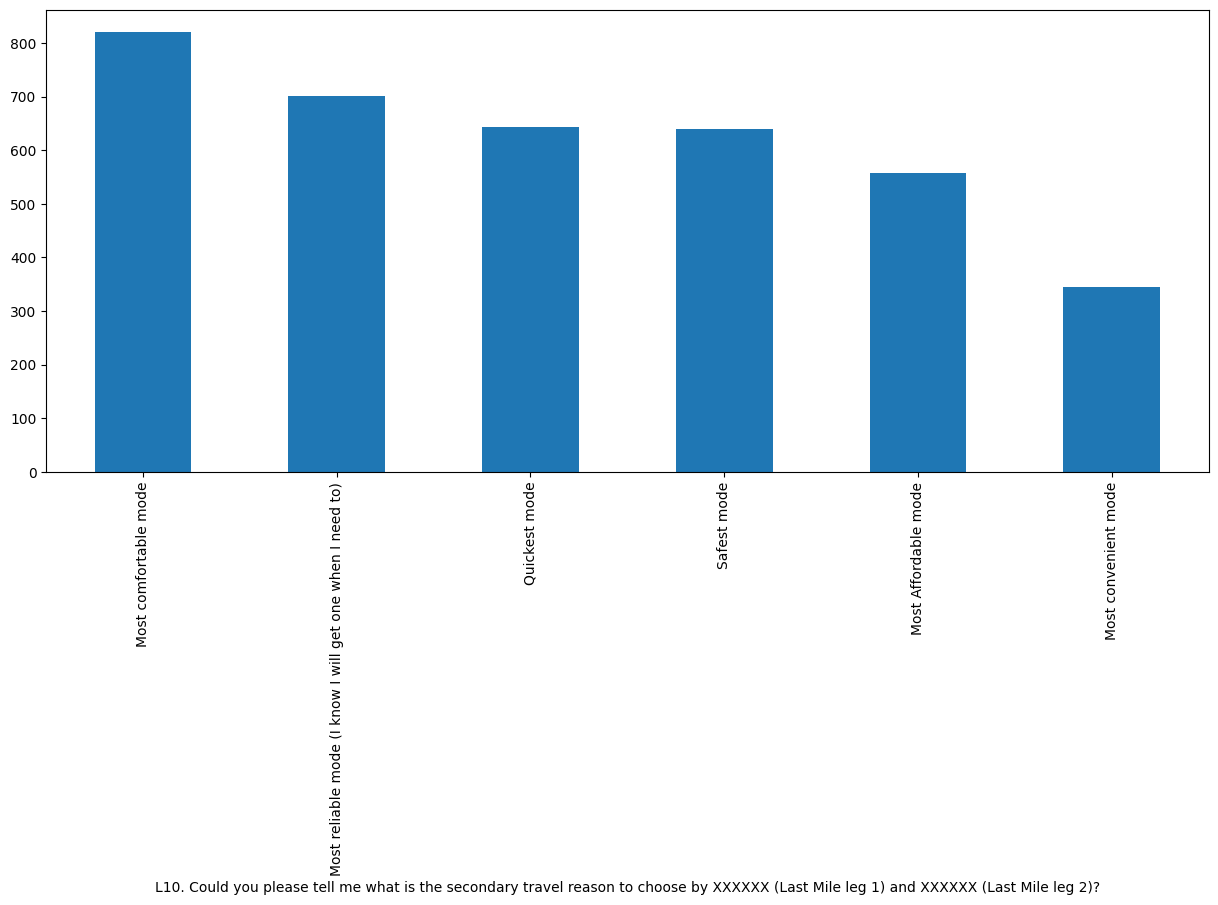

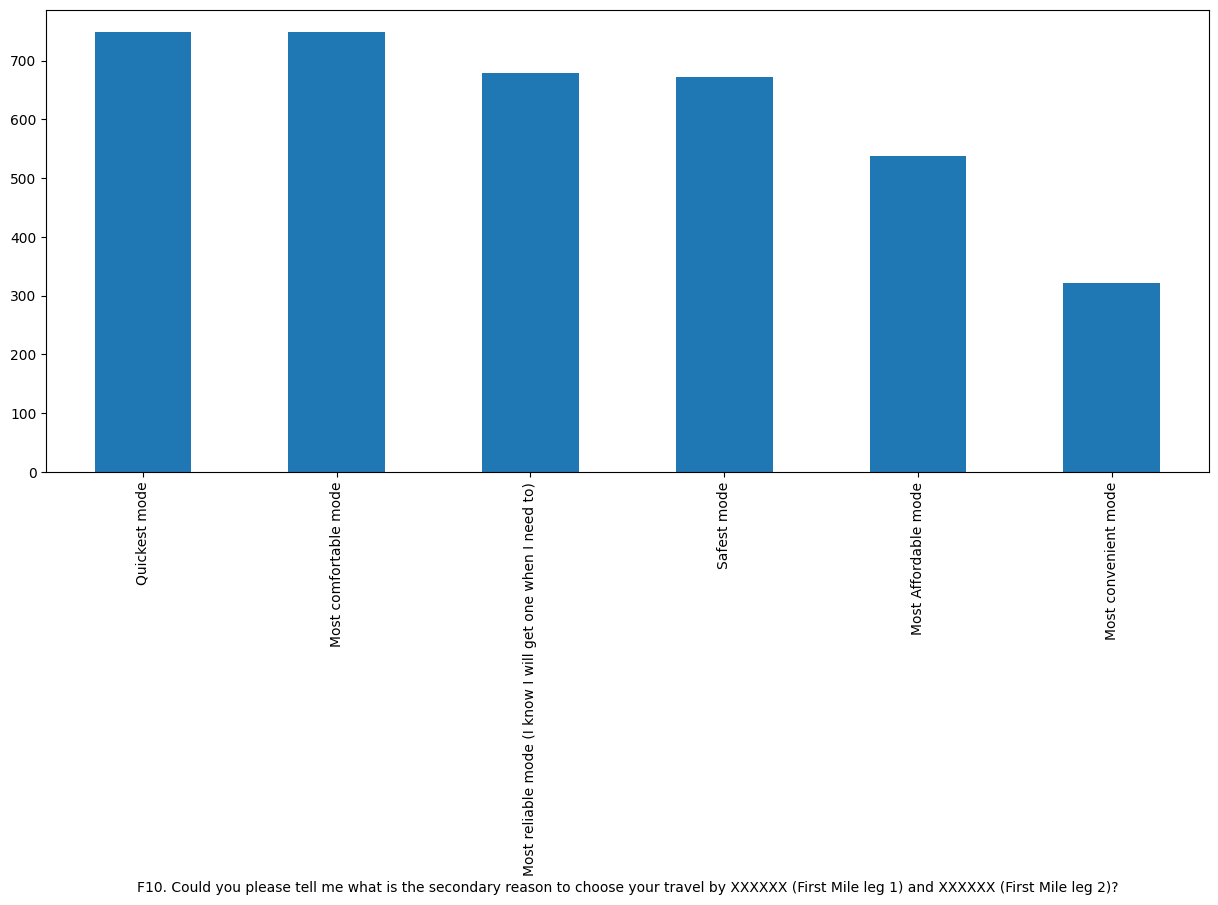

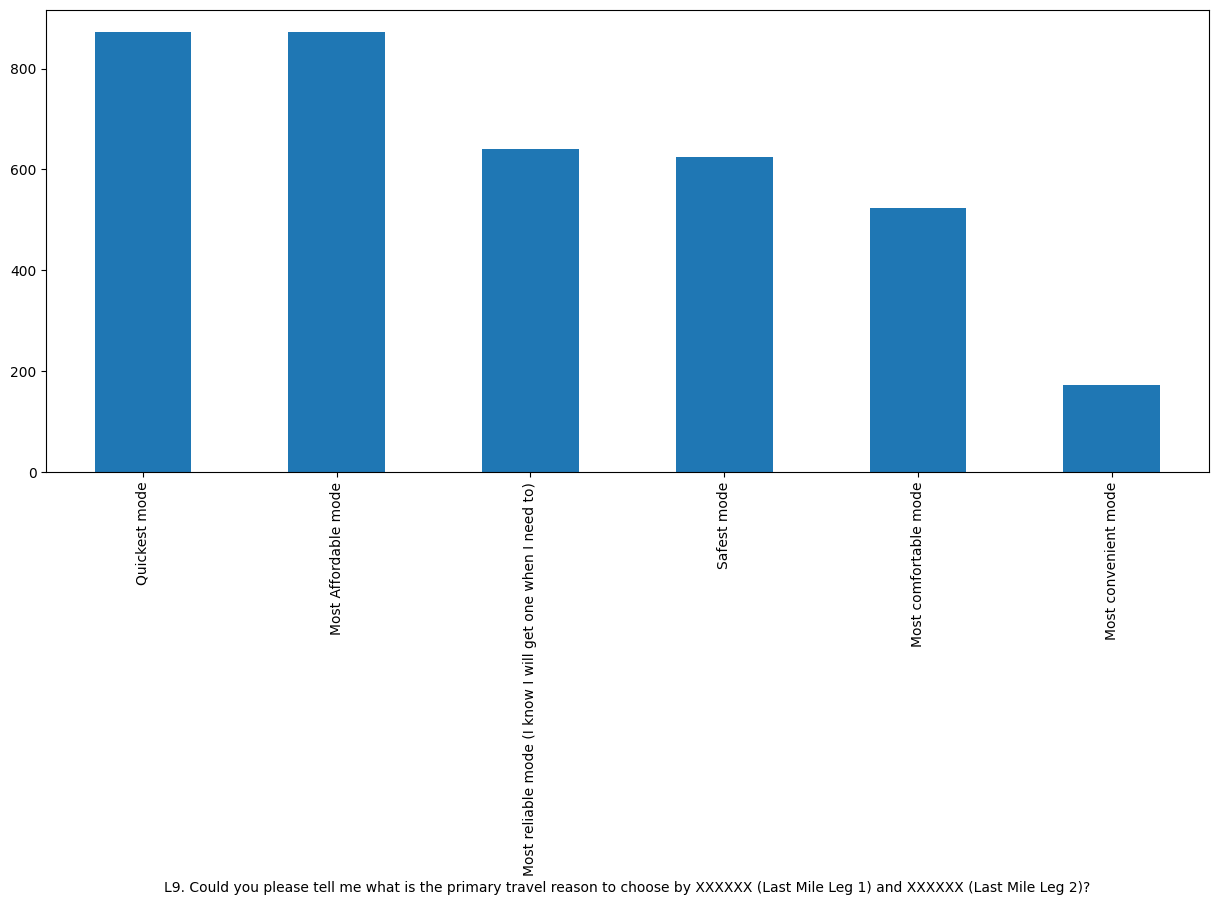

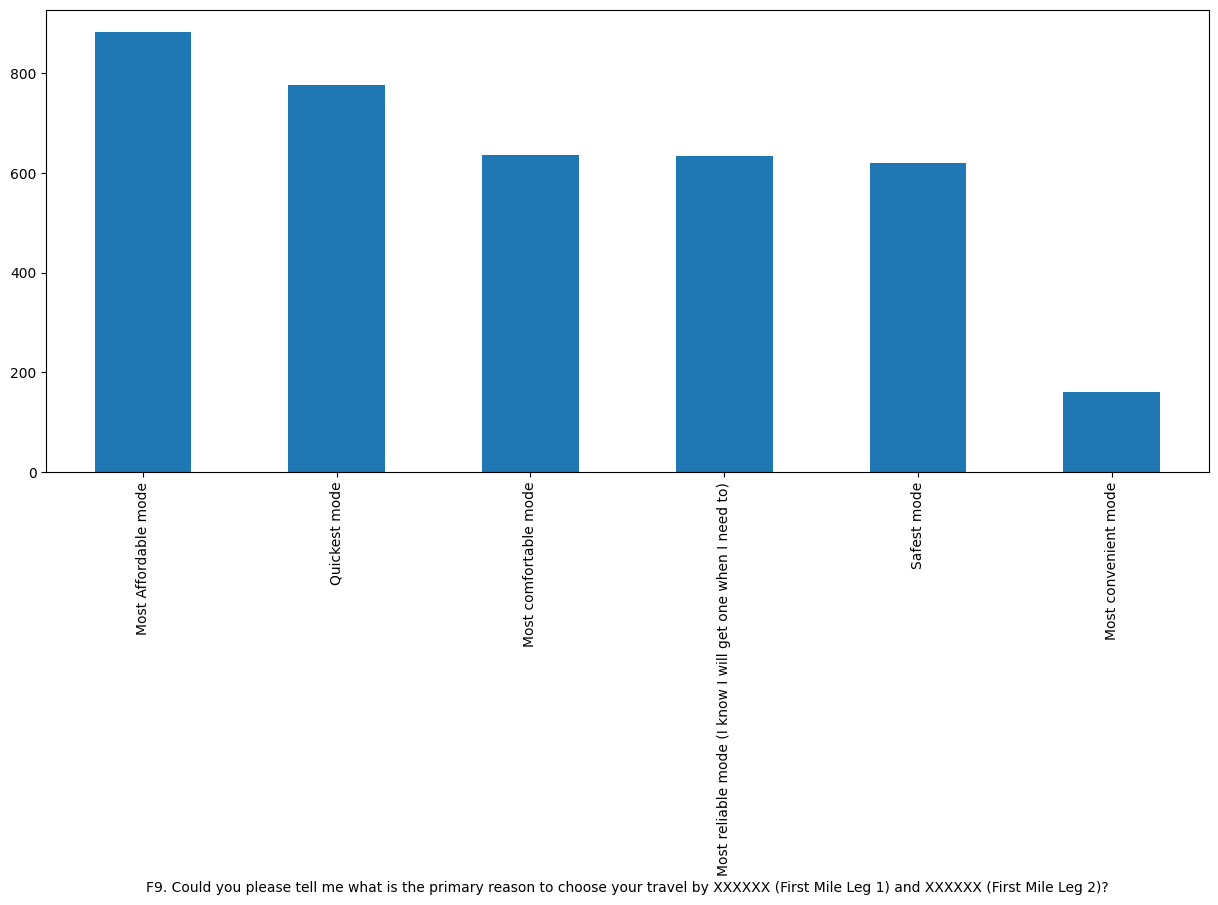

In [590]:
# F9. Could you please tell me what is the primary reason to choose your travel by XXXXXX (First Mile Leg 1) and XXXXXX (First Mile Leg 2)?
column_name_reason_first_mile = 'F9. Could you please tell me what is the primary reason to choose your travel by XXXXXX (First Mile Leg 1) and XXXXXX (First Mile Leg 2)?'

# F10. Could you please tell me what is the secondary reason to choose your travel by XXXXXX (First Mile leg 1) and XXXXXX (First Mile leg 2)?
column_name_secondary_reason_first_mile = 'F10. Could you please tell me what is the secondary reason to choose your travel by XXXXXX (First Mile leg 1) and XXXXXX (First Mile leg 2)?'

#L9. Could you please tell me what is the primary travel reason to choose by XXXXXX (Last Mile Leg 1) and XXXXXX (Last Mile Leg 2)?
column_name_reason_last_mile = 'L9. Could you please tell me what is the primary travel reason to choose by XXXXXX (Last Mile Leg 1) and XXXXXX (Last Mile Leg 2)?'

#L10. Could you please tell me what is the secondary travel reason to choose by XXXXXX (Last Mile leg 1) and XXXXXX (Last Mile leg 2)?

column_name_secondary_reason_last_mile = 'L10. Could you please tell me what is the secondary travel reason to choose by XXXXXX (Last Mile leg 1) and XXXXXX (Last Mile leg 2)?'



# Value counts
print(d[column_name_secondary_reason_last_mile].value_counts())
print(d[column_name_secondary_reason_first_mile].value_counts())
print(d[column_name_reason_last_mile].value_counts())
print(d[column_name_reason_first_mile].value_counts())

# Graphical representation
plt.figure(figsize=(15,6))
d[column_name_secondary_reason_last_mile].value_counts().plot(kind='bar')
plt.figure(figsize=(15,6))
d[column_name_secondary_reason_first_mile].value_counts().plot(kind='bar')
plt.figure(figsize=(15,6))
d[column_name_reason_last_mile].value_counts().plot(kind='bar')
plt.figure(figsize=(15,6))
d[column_name_reason_first_mile].value_counts().plot(kind='bar')

In [591]:
# F1.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip time in minute
column_name_trip_time_first_mile_leg_1 = 'F1.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip time in minute'
# Null values in trip time leg 1
null_values_trip_time_leg_1 = d[column_name_trip_time_first_mile_leg_1].isnull().sum()
print(f"Number of null values in 'Trip time by first mile connection (Leg 1)': {null_values_trip_time_leg_1}")

print(d[column_name_trip_time_first_mile_leg_1].describe())


d1 = d.copy()


print(d1[column_name_trip_time_first_mile_leg_1].describe())
mean_column_name_trip_time_first_mile_leg_1 = d1[column_name_trip_time_first_mile_leg_1].mean()
print(f"Mean of '{column_name_trip_time_first_mile_leg_1}': {mean_column_name_trip_time_first_mile_leg_1}")
median_column_name_trip_time_first_mile_leg_1 = d1[column_name_trip_time_first_mile_leg_1].median()
print(f"Median of '{column_name_trip_time_first_mile_leg_1}': {median_column_name_trip_time_first_mile_leg_1}")
mode_column_name_trip_time_first_mile_leg_1 = d1[column_name_trip_time_first_mile_leg_1].mode()[0]
print(f"Mode of '{column_name_trip_time_first_mile_leg_1}': {   mode_column_name_trip_time_first_mile_leg_1}")
variance_column_name_trip_time_first_mile_leg_1 = d1[column_name_trip_time_first_mile_leg_1].var()
print(f"Variance of '{column_name_trip_time_first_mile_leg_1}': {variance_column_name_trip_time_first_mile_leg_1}")
print(len(d1), len(d))

Number of null values in 'Trip time by first mile connection (Leg 1)': 0
count    3708.000000
mean       11.773732
std         6.295424
min         2.000000
25%         7.000000
50%        10.000000
75%        15.000000
max        60.000000
Name: F1.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip time in minute, dtype: float64
count    3708.000000
mean       11.773732
std         6.295424
min         2.000000
25%         7.000000
50%        10.000000
75%        15.000000
max        60.000000
Name: F1.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip time in minute, dtype: float64
Mean of 'F1.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip time in minute': 11.773732470334412
Median of 'F1.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip time in minute': 10.0
Mod

In [592]:
# F5.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip time in minute
column_name_trip_time_First_mile_leg_2 = 'F5.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip time in minute'
# Null values in trip time leg 2
null_values_trip_time_leg_2 = d[column_name_trip_time_First_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Trip time by first mile connection (Leg 2)': {null_values_trip_time_leg_2}")

for index, row in d1.iterrows():
    if row[column_name_First_mile_leg_2] == "No First mile leg 2":
        d1.at[index, column_name_trip_time_First_mile_leg_2] = 0

null_values_trip_time_leg_2_after = d1[column_name_trip_time_First_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Trip time by first mile connection (Leg 2)' after filling: {null_values_trip_time_leg_2_after}")


print(d1[column_name_trip_time_First_mile_leg_2].describe())

# Values > 50 count
print(d1[d1[column_name_trip_time_First_mile_leg_2] > 30][column_name_trip_time_First_mile_leg_2].count())

# Drop values > 30
d1 = d1[d1[column_name_trip_time_First_mile_leg_2] <= 30]

print(d1[column_name_trip_time_First_mile_leg_2].describe())
mean_column_name_trip_time_First_mile_leg_2 = d1[column_name_trip_time_First_mile_leg_2].mean()
print(f"Mean of '{column_name_trip_time_First_mile_leg_2}': {mean_column_name_trip_time_First_mile_leg_2}")
median_column_name_trip_time_First_mile_leg_2 = d1[column_name_trip_time_First_mile_leg_2].median()
print(f"Median of '{column_name_trip_time_First_mile_leg_2}': {median_column_name_trip_time_First_mile_leg_2}")
mode_column_name_trip_time_First_mile_leg_2 = d1[column_name_trip_time_First_mile_leg_2].mode()[0]
print(f"Mode of '{column_name_trip_time_First_mile_leg_2}': {mode_column_name_trip_time_First_mile_leg_2}")
variance_column_name_trip_time_First_mile_leg_2 = d1[column_name_trip_time_First_mile_leg_2].var()
print(f"Variance of '{column_name_trip_time_First_mile_leg_2}': {variance_column_name_trip_time_First_mile_leg_2}")

Number of null values in 'Trip time by first mile connection (Leg 2)': 2167
Number of null values in 'Trip time by first mile connection (Leg 2)' after filling: 0
count    3708.000000
mean        6.884574
std        10.087245
min         0.000000
25%         0.000000
50%         0.000000
75%        15.000000
max       150.000000
Name: F5.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip time in minute, dtype: float64
64
count    3644.000000
mean        6.234632
std         8.443421
min         0.000000
25%         0.000000
50%         0.000000
75%        15.000000
max        30.000000
Name: F5.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip time in minute, dtype: float64
Mean of 'F5.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip time in minute': 6.23463227222832
Median of 'F5.  How many minutes is your trip by xxxx 

In [593]:
# Mode Share in First Mile Connectivity
d1['First Mile Mode Sharing'] = d1[column_name_first_mile_leg_1] + ' + ' + d1[column_name_First_mile_leg_2]

# Mode Share Trip Time in First Mile Connectivity
d1['First Mile Mode share Trip Time'] = d1[column_name_trip_time_first_mile_leg_1] + d1[column_name_trip_time_First_mile_leg_2]


In [594]:
# P1. How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 1 - Trip time in minute
column_name_trip_time_primary_leg_1 = 'P1. How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 1 - Trip time in minute'
# Null values in trip time primary leg 1
null_values_trip_time_primary_leg_1 = d1[column_name_trip_time_primary_leg_1].isnull().sum()
print(f"Number of null values in 'Trip time by primary leg 1': {null_values_trip_time_primary_leg_1}")



for mode in d1[column_name_primary_mode_leg_1].unique():
    mode_filter = d1[column_name_primary_mode_leg_1] == mode
    mode_data = d1[mode_filter]
    mean_trip_time = mode_data[column_name_trip_time_primary_leg_1].mean()
    d1.loc[mode_filter & d1[column_name_trip_time_primary_leg_1].isnull(), column_name_trip_time_primary_leg_1] = mean_trip_time

null_values_trip_time_primary_leg_1_after = d1[column_name_trip_time_primary_leg_1].isnull().sum()
print(f"Number of null values in 'Trip time by primary leg 1' after filling: {null_values_trip_time_primary_leg_1_after}")


#values >100
print(d1[d1[column_name_trip_time_primary_leg_1] > 100][column_name_trip_time_primary_leg_1].count())

# Drop values > 100
d1 = d1[d1[column_name_trip_time_primary_leg_1] <= 100]
print(d1[column_name_trip_time_primary_leg_1].describe())
mean_column_name_trip_time_primary_leg_1 = d1[column_name_trip_time_primary_leg_1].mean()
print(f"Mean of '{column_name_trip_time_primary_leg_1}': {mean_column_name_trip_time_primary_leg_1}")
median_column_name_trip_time_primary_leg_1 = d1[column_name_trip_time_primary_leg_1].median()
print(f"Median of '{column_name_trip_time_primary_leg_1}': {median_column_name_trip_time_primary_leg_1}")
mode_column_name_trip_time_primary_leg_1 = d1[column_name_trip_time_primary_leg_1].mode()[0]
print(f"Mode of '{column_name_trip_time_primary_leg_1}': {mode_column_name_trip_time_primary_leg_1}")
variance_column_name_trip_time_primary_leg_1 = d1[column_name_trip_time_primary_leg_1].var()
print(f"Variance of '{column_name_trip_time_primary_leg_1}': {variance_column_name_trip_time_primary_leg_1}")


Number of null values in 'Trip time by primary leg 1': 0
Number of null values in 'Trip time by primary leg 1' after filling: 0
9
count    3635.000000
mean       35.672077
std        15.183786
min         1.000000
25%        25.000000
50%        35.000000
75%        45.000000
max        90.000000
Name: P1. How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 1 - Trip time in minute, dtype: float64
Mean of 'P1. How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 1 - Trip time in minute': 35.67207702888583
Median of 'P1. How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 1 - Trip time in minute': 35.0
Mode of 'P1. How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 1 - Trip time in minute': 40.0
Variance of 'P1. How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 1 - Trip time in minute': 230.54736263578204


In [595]:
# Q7.  How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 2 - Trip time in minute
column_name_trip_time_primary_leg_2 = 'P5.  How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 2 - Trip time in minute'
# Null values in trip time primary leg 2
null_values_trip_time_primary_leg_2 = d1[column_name_trip_time_primary_leg_2].isnull().sum()
print(f"Number of null values in 'Trip time by primary leg 2': {null_values_trip_time_primary_leg_2}")

for index, row in d1.iterrows():
    if row[column_name_primary_mode_leg_2] == "No Primary mode leg 2":
        d1.at[index, column_name_trip_time_primary_leg_2] = 0
null_values_trip_time_primary_leg_2_after = d1[column_name_trip_time_primary_leg_2].isnull().sum()
print(f"Number of null values in 'Trip time by primary leg 2' after filling: {null_values_trip_time_primary_leg_2_after}")

for mode in d1[column_name_primary_mode_leg_2].unique():
    mode_filter = d1[column_name_primary_mode_leg_2] == mode
    mode_data = d1[mode_filter]
    mean_trip_time = mode_data[column_name_trip_time_primary_leg_2].mean()
    d1.loc[mode_filter & d1[column_name_trip_time_primary_leg_2].isnull(), column_name_trip_time_primary_leg_2] = mean_trip_time


null_values_trip_time_primary_leg_2_after = d1[column_name_trip_time_primary_leg_2].isnull().sum()
print(f"Number of null values in 'Trip time by primary leg 2' after filling: {null_values_trip_time_primary_leg_2_after}")



# Values > 50 count
print(d1[d1[column_name_trip_time_primary_leg_2] > 60][column_name_trip_time_primary_leg_2].count())

# Drop values > 60
d1 = d1[d1[column_name_trip_time_primary_leg_2] <= 60]
print(d1[column_name_trip_time_primary_leg_2].describe())

mean_column_name_trip_time_primary_leg_2 = d1[column_name_trip_time_primary_leg_2].mean()
print(f"Mean of '{column_name_trip_time_primary_leg_2}': {mean_column_name_trip_time_primary_leg_2}")
median_column_name_trip_time_primary_leg_2 = d1[column_name_trip_time_primary_leg_2].median()
print(f"Median of '{column_name_trip_time_primary_leg_2}': {median_column_name_trip_time_primary_leg_2}")
mode_column_name_trip_time_primary_leg_2 = d1[column_name_trip_time_primary_leg_2].mode()[0]
print(f"Mode of '{column_name_trip_time_primary_leg_2}': {mode_column_name_trip_time_primary_leg_2}")
variance_column_name_trip_time_primary_leg_2 = d1[column_name_trip_time_primary_leg_2].var()
print(f"Variance of '{column_name_trip_time_primary_leg_2}': {variance_column_name_trip_time_primary_leg_2}")

Number of null values in 'Trip time by primary leg 2': 3466
Number of null values in 'Trip time by primary leg 2' after filling: 0
Number of null values in 'Trip time by primary leg 2' after filling: 0
30
count    3605.000000
mean        1.376144
std         7.507191
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        60.000000
Name: P5.  How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 2 - Trip time in minute, dtype: float64
Mean of 'P5.  How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 2 - Trip time in minute': 1.3761442441054093
Median of 'P5.  How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 2 - Trip time in minute': 0.0
Mode of 'P5.  How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 2 - Trip time in minute': 0.0
Variance of 'P5.  How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 2 - Trip time 

In [596]:
# Mode Share in Primary Connectivity
d1['Primary Mode Sharing'] = d1[column_name_primary_mode_leg_1] + ' + ' + d1[column_name_primary_mode_leg_2]
primary_mode_share = d1['Primary Mode Sharing'].value_counts()

d1['Primary Mode share Trip Time'] = d1[column_name_trip_time_primary_leg_1] + d1[column_name_trip_time_primary_leg_2]


In [597]:
# L1.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip time in minute
column_name_trip_time_last_mile_leg_1 = 'L1.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip time in minute'
# Null values in trip time last mile leg 1
null_values_trip_time_last_mile_leg_1 = d1[column_name_trip_time_last_mile_leg_1].isnull().sum()
print(f"Number of null values in 'Trip time by last mile connection (Leg 1)': {null_values_trip_time_last_mile_leg_1}")





# Values > 50 and <4 count
print(d1[d1[column_name_trip_time_last_mile_leg_1] > 50][column_name_trip_time_last_mile_leg_1].count())
print(d1[d1[column_name_trip_time_last_mile_leg_1] < 4][column_name_trip_time_last_mile_leg_1].count())

# Drop values > 50 and <4
d1 = d1[d1[column_name_trip_time_last_mile_leg_1] <= 50]
d1 = d1[d1[column_name_trip_time_last_mile_leg_1] >= 4]

print(d1[column_name_trip_time_last_mile_leg_1].describe())

mean_column_name_trip_time_last_mile_leg_1 = d1[column_name_trip_time_last_mile_leg_1].mean()
print(f"Mean of '{column_name_trip_time_last_mile_leg_1}': {mean_column_name_trip_time_last_mile_leg_1}")
median_column_name_trip_time_last_mile_leg_1 = d1[column_name_trip_time_last_mile_leg_1].median()
print(f"Median of '{column_name_trip_time_last_mile_leg_1}': {median_column_name_trip_time_last_mile_leg_1}")
mode_column_name_trip_time_last_mile_leg_1 = d1[column_name_trip_time_last_mile_leg_1].mode()[0]
print(f"Mode of '{column_name_trip_time_last_mile_leg_1}': {mode_column_name_trip_time_last_mile_leg_1}")
variance_column_name_trip_time_last_mile_leg_1 = d1[column_name_trip_time_last_mile_leg_1].var()
print(f"Variance of '{column_name_trip_time_last_mile_leg_1}': {variance_column_name_trip_time_last_mile_leg_1}")

Number of null values in 'Trip time by last mile connection (Leg 1)': 0
11
86
count    3508.000000
mean       11.822406
std         6.856847
min         4.000000
25%         7.000000
50%        10.000000
75%        15.000000
max        50.000000
Name: L1.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip time in minute, dtype: float64
Mean of 'L1.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip time in minute': 11.822405929304447
Median of 'L1.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip time in minute': 10.0
Mode of 'L1.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip time in minute': 10.0
Variance of 'L1.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip time in minute': 47.016355544327524


In [598]:
# Q7L5.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip time in minute
column_name_trip_time_last_mile_leg_2 = 'L5.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip time in minute'
d2 = d1.copy()

# Null values in trip time last mile leg 2
null_values_trip_time_last_mile_leg_2 = d2[column_name_trip_time_last_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Trip time by last mile connection (Leg 2)': {null_values_trip_time_last_mile_leg_2}")

for index, row in d2.iterrows():
    if row[column_name_last_mile_leg_2] == "No Last mile leg 2":
        d2.at[index, column_name_trip_time_last_mile_leg_2] = 0
        

# Values > 30
print(d2[d2[column_name_trip_time_last_mile_leg_2] > 30][column_name_trip_time_last_mile_leg_2].count())

# Drop values > 30
d2 = d2[d2[column_name_trip_time_last_mile_leg_2] <= 30]

print(d2[column_name_trip_time_last_mile_leg_2].describe())
mean_column_name_trip_time_first_mile_leg_12 = d2[column_name_trip_time_last_mile_leg_2].mean()
print(f"Mean of '{column_name_trip_time_last_mile_leg_2}': {mean_column_name_trip_time_first_mile_leg_12}")
median_column_name_trip_time_first_mile_leg_12 = d2[column_name_trip_time_last_mile_leg_2].median()
print(f"Median of '{column_name_trip_time_last_mile_leg_2}': {median_column_name_trip_time_first_mile_leg_12}")
mode_column_name_trip_time_first_mile_leg_12 = d2[column_name_trip_time_last_mile_leg_2].mode()[0]
print(f"Mode of '{column_name_trip_time_last_mile_leg_2}': {mode_column_name_trip_time_first_mile_leg_12}")
variance_column_name_trip_time_first_mile_leg_12 = d2[column_name_trip_time_last_mile_leg_2].var()
print(f"Variance of '{column_name_trip_time_last_mile_leg_2}': {variance_column_name_trip_time_first_mile_leg_12}")


Number of null values in 'Trip time by last mile connection (Leg 2)': 2811
34
count    3474.000000
mean        2.621186
std         5.821401
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        30.000000
Name: L5.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip time in minute, dtype: float64
Mean of 'L5.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip time in minute': 2.6211859527921706
Median of 'L5.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip time in minute': 0.0
Mode of 'L5.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip time in minute': 0.0
Variance of 'L5.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip time in minute': 33.88870737514382


In [599]:
# Mode share in Last Mile Connectivity
d2['Last Mile Mode Sharing'] = d2[column_name_last_mile_leg_1] + ' + ' + d2[column_name_last_mile_leg_2]
last_mile_mode_share = d2['Last Mile Mode Sharing'].value_counts()

d2['Last Mile Mode share Trip Time'] = d2[column_name_trip_time_last_mile_leg_1] + d2[column_name_trip_time_last_mile_leg_2]



In [600]:
# Q7F2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - First mile connection (Leg 1) - Wait time in minute

column_name_wait_time_first_mile_leg_1 = 'F2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - First mile connection (Leg 1) - Wait time in minute'
# Null values in wait time first mile leg 1
null_values_wait_time_first_mile_leg_1 = d2[column_name_wait_time_first_mile_leg_1].isnull().sum()
print(f"Number of null values in 'Wait time for first mile connection (Leg 1)': {null_values_wait_time_first_mile_leg_1}")


# Fill null values with mean
mean_wait_time_first_mile_leg_1 = d2[column_name_wait_time_first_mile_leg_1].mean()
d2[column_name_wait_time_first_mile_leg_1].fillna(mean_wait_time_first_mile_leg_1, inplace=True)


print(d2[column_name_wait_time_first_mile_leg_1].describe())
mean_column_name_wait_time_first_mile_leg_1 = d2[column_name_wait_time_first_mile_leg_1].mean()
print(f"Mean of '{column_name_wait_time_first_mile_leg_1}': {mean_column_name_wait_time_first_mile_leg_1}")
median_column_name_wait_time_first_mile_leg_1 = d2[column_name_wait_time_first_mile_leg_1].median()
print(f"Median of '{column_name_wait_time_first_mile_leg_1}': {median_column_name_wait_time_first_mile_leg_1}")
mode_column_name_wait_time_first_mile_leg_1 = d2[column_name_wait_time_first_mile_leg_1].mode()[0]
print(f"Mode of '{column_name_wait_time_first_mile_leg_1}': {mode_column_name_wait_time_first_mile_leg_1}")
variance_column_name_wait_time_first_mile_leg_1 = d2[column_name_wait_time_first_mile_leg_1].var()
print(f"Variance of '{column_name_wait_time_first_mile_leg_1}': {variance_column_name_wait_time_first_mile_leg_1}")


Number of null values in 'Wait time for first mile connection (Leg 1)': 2655
count    3474.000000
mean        5.394383
std         1.758498
min         0.000000
25%         5.394383
50%         5.394383
75%         5.394383
max        29.000000
Name: F2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - First mile connection (Leg 1) - Wait time in minute, dtype: float64
Mean of 'F2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - First mile connection (Leg 1) - Wait time in minute': 5.3943833943833965
Median of 'F2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - First mile connection (Leg 1) - Wait time in minute': 5.394383394383395
Mode of 'F2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - First mile connection (Leg 1) - Wait time in minute': 5.394383394383395
Variance of 'F2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Fi

C:\Users\maddi\AppData\Local\Temp\ipykernel_12412\3889065409.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d2[column_name_wait_time_first_mile_leg_1].fillna(mean_wait_time_first_mile_leg_1, inplace=True)


In [601]:
# Q7F6.  How many minutes do you spend on waiting for xxxx (mentioned automatically)?  - First mile connection (Leg 2) - Wait time in minute
column_name_wait_time_first_mile_leg_2 = 'F6.  How many minutes do you spend on waiting for xxxx (mentioned automatically)?  - First mile connection (Leg 2) - Wait time in minute'
# Null values in wait time first mile leg 2
null_values_wait_time_first_mile_leg_2 = d2[column_name_wait_time_first_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Wait time for first mile connection (Leg 2)': {null_values_wait_time_first_mile_leg_2}")

for index, row in d2.iterrows():
    if row[column_name_First_mile_leg_2] == "No First mile leg 2":
        d2.at[index, column_name_wait_time_first_mile_leg_2] = 0

null_values_wait_time_first_mile_leg_2_after = d2[column_name_wait_time_first_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Wait time for first mile connection (Leg 2)' after filling: {null_values_wait_time_first_mile_leg_2_after}")


# FIll null values with mean
d2[column_name_wait_time_first_mile_leg_2].fillna(d2[column_name_wait_time_first_mile_leg_2].mean(), inplace=True)

print(d2[column_name_wait_time_first_mile_leg_2].describe())
mean_column_name_wait_time_first_mile_leg_2 = d2[column_name_wait_time_first_mile_leg_2].mean()
print(f"Mean of '{column_name_wait_time_first_mile_leg_2}': {mean_column_name_wait_time_first_mile_leg_2}")
median_column_name_wait_time_first_mile_leg_2 = d2[column_name_wait_time_first_mile_leg_2].median()
print(f"Median of '{column_name_wait_time_first_mile_leg_2}': {median_column_name_wait_time_first_mile_leg_2}")
mode_column_name_wait_time_first_mile_leg_2 = d2[column_name_wait_time_first_mile_leg_2].mode()[0]
print(f"Mode of '{column_name_wait_time_first_mile_leg_2}': {mode_column_name_wait_time_first_mile_leg_2}")
variance_column_name_wait_time_first_mile_leg_2 = d2[column_name_wait_time_first_mile_leg_2].var()
print(f"Variance of '{column_name_wait_time_first_mile_leg_2}': {variance_column_name_wait_time_first_mile_leg_2}")

Number of null values in 'Wait time for first mile connection (Leg 2)': 2132
Number of null values in 'Wait time for first mile connection (Leg 2)' after filling: 47
count    3474.000000
mean        2.923548
std         4.275563
min         0.000000
25%         0.000000
50%         0.000000
75%         5.000000
max        25.000000
Name: F6.  How many minutes do you spend on waiting for xxxx (mentioned automatically)?  - First mile connection (Leg 2) - Wait time in minute, dtype: float64
Mean of 'F6.  How many minutes do you spend on waiting for xxxx (mentioned automatically)?  - First mile connection (Leg 2) - Wait time in minute': 2.92354829296761
Median of 'F6.  How many minutes do you spend on waiting for xxxx (mentioned automatically)?  - First mile connection (Leg 2) - Wait time in minute': 0.0
Mode of 'F6.  How many minutes do you spend on waiting for xxxx (mentioned automatically)?  - First mile connection (Leg 2) - Wait time in minute': 0.0
Variance of 'F6.  How many minutes d

C:\Users\maddi\AppData\Local\Temp\ipykernel_12412\627843028.py:16: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d2[column_name_wait_time_first_mile_leg_2].fillna(d2[column_name_wait_time_first_mile_leg_2].mean(), inplace=True)


In [602]:
# Mode share in First Mile Connectivity - Wait Time
d2['First Mile Mode share Wait Time'] = d2[column_name_wait_time_first_mile_leg_1] + d2[column_name_wait_time_first_mile_leg_2]

In [603]:
# Q7P2. How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Primary Leg 1 - Wait time in minute
column_name_wait_time_primary_leg_1 = 'P2. How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Primary Leg 1 - Wait time in minute'
# Null values in wait time primary leg 1
null_values_wait_time_primary_leg_1 = d2[column_name_wait_time_primary_leg_1].isnull().sum()
print(f"Number of null values in 'Wait time for primary leg 1': {null_values_wait_time_primary_leg_1}")

print(d2[column_name_wait_time_primary_leg_1].describe())

# values > 30
print(d2[d2[column_name_wait_time_primary_leg_1] > 30][column_name_wait_time_primary_leg_1].count())
# Drop values > 30
d2 = d2[d2[column_name_wait_time_primary_leg_1] <= 30]

print(d2[column_name_wait_time_primary_leg_1].describe())
mean_column_name_wait_time_primary_leg_1 = d2[column_name_wait_time_primary_leg_1].mean()
print(f"Mean of '{column_name_wait_time_primary_leg_1}': {mean_column_name_wait_time_primary_leg_1}")
median_column_name_wait_time_primary_leg_1 = d2[column_name_wait_time_primary_leg_1].median()
print(f"Median of '{column_name_wait_time_primary_leg_1}': {median_column_name_wait_time_primary_leg_1}")
mode_column_name_wait_time_primary_leg_1 = d2[column_name_wait_time_primary_leg_1].mode()[0]
print(f"Mode of '{column_name_wait_time_primary_leg_1}': {mode_column_name_wait_time_primary_leg_1}")
variance_column_name_wait_time_primary_leg_1 = d2[column_name_wait_time_primary_leg_1].var()
print(f"Variance of '{column_name_wait_time_primary_leg_1}': {variance_column_name_wait_time_primary_leg_1}")

Number of null values in 'Wait time for primary leg 1': 0
count    3474.000000
mean        5.154577
std         2.884872
min         1.000000
25%         4.000000
50%         5.000000
75%         6.000000
max        70.000000
Name: P2. How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Primary Leg 1 - Wait time in minute, dtype: float64
3
count    3471.000000
mean        5.112936
std         2.487301
min         1.000000
25%         4.000000
50%         5.000000
75%         6.000000
max        30.000000
Name: P2. How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Primary Leg 1 - Wait time in minute, dtype: float64
Mean of 'P2. How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Primary Leg 1 - Wait time in minute': 5.112935753385192
Median of 'P2. How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Primary Leg 1 - Wait time in minute': 5.0
Mode of 'P2. How many minutes do you s

In [604]:
# Q7P6. How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Primary Leg 2 - Wait time in minute
column_name_wait_time_primary_leg_2 = 'P6. How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Primary Leg 2 - Wait time in minute'
# Null values in wait time primary leg 2
null_values_wait_time_primary_leg_2 = d2[column_name_wait_time_primary_leg_2].isnull().sum()
print(f"Number of null values in 'Wait time for primary leg 2': {null_values_wait_time_primary_leg_2}")

for index, row in d2.iterrows():
    if row[column_name_primary_mode_leg_2] == "No Primary mode leg 2":
        d2.at[index, column_name_wait_time_primary_leg_2] = 0

null_values_wait_time_primary_leg_2_after = d2[column_name_wait_time_primary_leg_2].isnull().sum()
print(f"Number of null values in 'Wait time for primary leg 2' after filling: {null_values_wait_time_primary_leg_2_after}")


print(d2[column_name_wait_time_primary_leg_2].describe())

Number of null values in 'Wait time for primary leg 2': 3353
Number of null values in 'Wait time for primary leg 2' after filling: 0
count    3471.000000
mean        0.343705
std         2.338807
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        30.000000
Name: P6. How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Primary Leg 2 - Wait time in minute, dtype: float64


In [605]:
# Mode Share in Primary Connectivity - Wait Time
d2['Primary Mode share Wait Time'] = d2[column_name_wait_time_primary_leg_1] + d2[column_name_wait_time_primary_leg_2]

In [606]:
# Q7L2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Last mile connection (leg 1) - Wait time in minute
column_name_wait_time_last_mile_leg_1 = 'L2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Last mile connection (leg 1) - Wait time in minute'
# Null values in wait time last mile leg 1
null_values_wait_time_last_mile_leg_1 = d2[column_name_wait_time_last_mile_leg_1].isnull().sum()
print(f"Number of null values in 'Wait time for last mile connection (Leg 1 )': {null_values_wait_time_last_mile_leg_1}")




print(d2[column_name_wait_time_last_mile_leg_1].describe())
mean_column_name_wait_time_last_mile_leg_1 = d2[column_name_wait_time_last_mile_leg_1].mean()
print(f"Mean of '{column_name_wait_time_last_mile_leg_1}': {mean_column_name_wait_time_last_mile_leg_1}")
median_column_name_wait_time_last_mile_leg_1 = d2[column_name_wait_time_last_mile_leg_1].median()
print(f"Median of '{column_name_wait_time_last_mile_leg_1}': {median_column_name_wait_time_last_mile_leg_1}")
mode_column_name_wait_time_last_mile_leg_1 = d2[column_name_wait_time_last_mile_leg_1].mode()[0]
print(f"Mode of '{column_name_wait_time_last_mile_leg_1}': {mode_column_name_wait_time_last_mile_leg_1}")
variance_column_name_wait_time_last_mile_leg_1 = d2[column_name_wait_time_last_mile_leg_1].var()
print(f"Variance of '{column_name_wait_time_last_mile_leg_1}': {variance_column_name_wait_time_last_mile_leg_1}")


Number of null values in 'Wait time for last mile connection (Leg 1 )': 2536
count    935.000000
mean       5.807487
std        3.321358
min        0.000000
25%        4.000000
50%        5.000000
75%        6.000000
max       25.000000
Name: L2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Last mile connection (leg 1) - Wait time in minute, dtype: float64
Mean of 'L2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Last mile connection (leg 1) - Wait time in minute': 5.807486631016043
Median of 'L2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Last mile connection (leg 1) - Wait time in minute': 5.0
Mode of 'L2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Last mile connection (leg 1) - Wait time in minute': 4.0
Variance of 'L2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Last mile connection (leg 1) - Wait time in

In [607]:
#Q7L6.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Last mile connection (leg 2) - Wait time in minute

column_name_wait_time_last_mile_leg_2 = 'L6.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Last mile connection (leg 2) - Wait time in minute'
# Null values in wait time last mile leg 2
null_values_wait_time_last_mile_leg_2 = d2[column_name_wait_time_last_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Wait time for last mile connection (Leg 2)': {null_values_wait_time_last_mile_leg_2}")


for index, row in d2.iterrows():
    if row[column_name_last_mile_leg_2] == "No Last mile leg 2":
        d2.at[index, column_name_wait_time_last_mile_leg_2] = 0

null_values_wait_time_last_mile_leg_2_after = d2[column_name_wait_time_last_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Wait time for last mile connection (Leg 2)' after filling: {null_values_wait_time_last_mile_leg_2_after}")


# Fill with mean
d2[column_name_wait_time_last_mile_leg_2].fillna(d2[column_name_wait_time_last_mile_leg_2].mean(), inplace=True)

print(d2[column_name_wait_time_last_mile_leg_2].describe())
# mean_column_name_wait_time_last_mile_leg_2 = d2[column_name_wait_time_last_mile_leg_2].mean()

# print(f"Mean of '{column_name_wait_time_last_mile_leg_2}': {mean_column_name_wait_time_last_mile_leg_2}")
# median_column_name_wait_time_last_mile_leg_2 = d2[column_name_wait_time_last_mile_leg_2].median()
# print(f"Median of '{column_name_wait_time_last_mile_leg_2}': {median_column_name_wait_time_last_mile_leg_2}")
# mode_column_name_wait_time_last_mile_leg_2 = d2[column_name_wait_time_last_mile_leg_2].mode()[0]
# print(f"Mode of '{column_name_wait_time_last_mile_leg_2}': {mode_column_name_wait_time_last_mile_leg_2}")
# variance_column_name_wait_time_last_mile_leg_2 = d2[column_name_wait_time_last_mile_leg_2].var()
# print(f"Variance of '{column_name_wait_time_last_mile_leg_2}': {variance_column_name_wait_time_last_mile_leg_2}")


Number of null values in 'Wait time for last mile connection (Leg 2)': 3105
Number of null values in 'Wait time for last mile connection (Leg 2)' after filling: 297
count    3471.000000
mean        1.098299
std         3.200474
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        25.000000
Name: L6.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Last mile connection (leg 2) - Wait time in minute, dtype: float64


C:\Users\maddi\AppData\Local\Temp\ipykernel_12412\2962290254.py:18: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d2[column_name_wait_time_last_mile_leg_2].fillna(d2[column_name_wait_time_last_mile_leg_2].mean(), inplace=True)


In [608]:
# Mode share in Last Mile Connectivity - Wait Time
d2['Last Mile Mode share Wait Time'] = d2[column_name_wait_time_last_mile_leg_1] + d2[column_name_wait_time_last_mile_leg_2]


len(d2)

3471

In [609]:
# Q7F3.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip Cost (In Rupees) :
column_name_trip_cost_first_mile_leg_1 = 'F3.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip Cost (In Rupees) :'



# Null values in trip cost first mile leg 1
null_values_trip_cost_first_mile_leg_1 = d2[column_name_trip_cost_first_mile_leg_1].isnull().sum()
print(f"Number of null values in 'Trip cost for first mile connection (Leg 1)': {null_values_trip_cost_first_mile_leg_1}")






for mode in d2[column_name_first_mile_leg_1].unique():

    mode_filter = d2[column_name_first_mile_leg_1] == mode

    if mode == "Walk":
        d2.loc[mode_filter & d2[column_name_trip_cost_first_mile_leg_1].isnull(), column_name_trip_cost_first_mile_leg_1] = 0

    else:
        mode_data = d2[mode_filter]
        mean_trip_cost = mode_data[column_name_trip_cost_first_mile_leg_1].mean()
        d2.loc[mode_filter & d2[column_name_trip_cost_first_mile_leg_1].isnull(), column_name_trip_cost_first_mile_leg_1] = mean_trip_cost




null_values_trip_cost_first_mile_leg_1_after = d2[column_name_trip_cost_first_mile_leg_1].isnull().sum()
print(f"Number of null values in 'Trip cost for first mile connection (Leg 1)' after filling: {null_values_trip_cost_first_mile_leg_1_after}")




print(d2[column_name_trip_cost_first_mile_leg_1].describe())
mean_column_name_trip_cost_first_mile_leg_1 = d2[column_name_trip_cost_first_mile_leg_1].mean()
print(f"Mean of '{column_name_trip_cost_first_mile_leg_1}': {mean_column_name_trip_cost_first_mile_leg_1}")
median_column_name_trip_cost_first_mile_leg_1 = d2[column_name_trip_cost_first_mile_leg_1].median()
print(f"Median of '{column_name_trip_cost_first_mile_leg_1}': {median_column_name_trip_cost_first_mile_leg_1}")
mode_column_name_trip_cost_first_mile_leg_1 = d2[column_name_trip_cost_first_mile_leg_1].mode()[0]
print(f"Mode of '{column_name_trip_cost_first_mile_leg_1}': {mode_column_name_trip_cost_first_mile_leg_1}")
variance_column_name_trip_cost_first_mile_leg_1 = d2[column_name_trip_cost_first_mile_leg_1].var()
print(f"Variance of '{column_name_trip_cost_first_mile_leg_1}': {variance_column_name_trip_cost_first_mile_leg_1}")

Number of null values in 'Trip cost for first mile connection (Leg 1)': 2624
Number of null values in 'Trip cost for first mile connection (Leg 1)' after filling: 0
count    3471.000000
mean        3.188441
std         6.890333
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       140.000000
Name: F3.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip Cost (In Rupees) :, dtype: float64
Mean of 'F3.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip Cost (In Rupees) :': 3.1884409194389365
Median of 'F3.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip Cost (In Rupees) :': 0.0
Mode of 'F3.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip Cost (In Rupees) :': 0.0
Variance of 'F3.  How much do you pay for the trip by xxxx 

In [610]:
# Q7F7.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip Cost (In Rupees) :
column_name_trip_cost_first_mile_leg_2 = 'F7.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip Cost (In Rupees) :'


# Null values in trip cost first mile leg 2
null_values_trip_cost_first_mile_leg_2 = d2[column_name_trip_cost_first_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Trip cost for first mile connection (Leg 2)': {null_values_trip_cost_first_mile_leg_2}")




for mode in d2[column_name_First_mile_leg_2].unique():

    mode_filter = d2[column_name_First_mile_leg_2] == mode

    if mode == "No First mile leg 2" or mode == "Walk":
        d2.loc[mode_filter & d2[column_name_trip_cost_first_mile_leg_2].isnull(), column_name_trip_cost_first_mile_leg_2] = 0

    
null_values_trip_cost_first_mile_leg_2_after = d2[column_name_trip_cost_first_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Trip cost for first mile connection (Leg 2)' after filling: {null_values_trip_cost_first_mile_leg_2_after}")

# Remove Null values if any still present
d2 = d2[d2[column_name_trip_cost_first_mile_leg_2].notnull()]

print(d2[column_name_trip_cost_first_mile_leg_2].describe())
mean_column_name_trip_cost_first_mile_leg_2 = d2[column_name_trip_cost_first_mile_leg_2].mean()
print(f"Mean of '{column_name_trip_cost_first_mile_leg_2}': {mean_column_name_trip_cost_first_mile_leg_2}")
median_column_name_trip_cost_first_mile_leg_2 = d2[column_name_trip_cost_first_mile_leg_2].median()
print(f"Median of '{column_name_trip_cost_first_mile_leg_2}': {median_column_name_trip_cost_first_mile_leg_2}")
mode_column_name_trip_cost_first_mile_leg_2 = d2[column_name_trip_cost_first_mile_leg_2].mode()[0]
print(f"Mode of '{column_name_trip_cost_first_mile_leg_2}': {mode_column_name_trip_cost_first_mile_leg_2}")
variance_column_name_trip_cost_first_mile_leg_2 = d2[column_name_trip_cost_first_mile_leg_2].var()
print(f"Variance of '{column_name_trip_cost_first_mile_leg_2}': {variance_column_name_trip_cost_first_mile_leg_2}")

Number of null values in 'Trip cost for first mile connection (Leg 2)': 2104
Number of null values in 'Trip cost for first mile connection (Leg 2)' after filling: 15
count    3456.000000
mean        5.758681
std         8.970167
min         0.000000
25%         0.000000
50%         0.000000
75%        10.000000
max       140.000000
Name: F7.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip Cost (In Rupees) :, dtype: float64
Mean of 'F7.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip Cost (In Rupees) :': 5.758680555555555
Median of 'F7.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip Cost (In Rupees) :': 0.0
Mode of 'F7.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip Cost (In Rupees) :': 0.0
Variance of 'F7.  How much do you pay for the trip by xxxx 

In [611]:
# Mode Share in First Mile Connectivity - Cost
d2['First Mile Mode share Cost'] = d2[column_name_trip_cost_first_mile_leg_1] + d2[column_name_trip_cost_first_mile_leg_2]

In [612]:
# Q7L3.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip Cost (In Rupees) :
column_name_trip_cost_last_mile_leg_1 = 'L3.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip Cost (In Rupees) :'




for mode in d2[column_name_last_mile_leg_1].unique():

    mode_filter = d2[column_name_last_mile_leg_1] == mode

    if mode == "Walk":
        d2.loc[mode_filter & d2[column_name_trip_cost_last_mile_leg_1].isnull(), column_name_trip_cost_last_mile_leg_1] = 0

    else:
        mode_data = d2[mode_filter]
        mean_trip_cost = mode_data[column_name_trip_cost_last_mile_leg_1].mean()
        d2.loc[mode_filter & d2[column_name_trip_cost_last_mile_leg_1].isnull(), column_name_trip_cost_last_mile_leg_1] = mean_trip_cost


# Fill with mean
d2[column_name_trip_cost_last_mile_leg_1].fillna(d2[column_name_trip_cost_last_mile_leg_1].mean(), inplace=True)

print(d2[column_name_trip_cost_last_mile_leg_1].describe())


print(d2[column_name_trip_cost_last_mile_leg_1].describe())
mean_column_name_trip_cost_last_mile_leg_1 = d2[column_name_trip_cost_last_mile_leg_1].mean()
print(f"Mean of '{column_name_trip_cost_last_mile_leg_1}': {mean_column_name_trip_cost_last_mile_leg_1}")
median_column_name_trip_cost_last_mile_leg_1 = d2[column_name_trip_cost_last_mile_leg_1].median()
print(f"Median of '{column_name_trip_cost_last_mile_leg_1}': {median_column_name_trip_cost_last_mile_leg_1}")
mode_column_name_trip_cost_last_mile_leg_1 = d2[column_name_trip_cost_last_mile_leg_1].mode()[0]
print(f"Mode of '{column_name_trip_cost_last_mile_leg_1}': {mode_column_name_trip_cost_last_mile_leg_1}")
variance_column_name_trip_cost_last_mile_leg_1 = d2[column_name_trip_cost_last_mile_leg_1].var()
print(f"Variance of '{column_name_trip_cost_last_mile_leg_1}': {variance_column_name_trip_cost_last_mile_leg_1}")

count    3456.000000
mean        3.785669
std         7.618717
min         0.000000
25%         0.000000
50%         0.000000
75%        10.000000
max       140.000000
Name: L3.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip Cost (In Rupees) :, dtype: float64
count    3456.000000
mean        3.785669
std         7.618717
min         0.000000
25%         0.000000
50%         0.000000
75%        10.000000
max       140.000000
Name: L3.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip Cost (In Rupees) :, dtype: float64
Mean of 'L3.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip Cost (In Rupees) :': 3.785669191919192
Median of 'L3.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip Cost (In Rupees) :': 0.0
Mode of 'L3.  How much do you pay for the trip by xxxx

C:\Users\maddi\AppData\Local\Temp\ipykernel_12412\3619523124.py:21: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d2[column_name_trip_cost_last_mile_leg_1].fillna(d2[column_name_trip_cost_last_mile_leg_1].mean(), inplace=True)


In [613]:
# Q7L5.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip time in minute
column_name_trip_cost_last_mile_leg_2 = 'L7.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip Cost (In Rupees) :'


# Null values in trip cost last mile leg 2
null_values_trip_cost_last_mile_leg_2 = d2[column_name_trip_cost_last_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Trip cost for last mile connection (Leg 2)': {null_values_trip_cost_last_mile_leg_2}")


for mode in d2[column_name_last_mile_leg_2].unique():
    mode_filter = d2[column_name_last_mile_leg_2] == mode

    if mode == "No Last mile leg 2" or mode == "Walk":
        d2.loc[mode_filter & d2[column_name_trip_cost_last_mile_leg_2].isnull(), column_name_trip_cost_last_mile_leg_2] = 0

    

null_values_trip_cost_last_mile_leg_2_after = d2[column_name_trip_cost_last_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Trip cost for last mile connection (Leg 2)' after filling: {null_values_trip_cost_last_mile_leg_2_after}")

# Remove Null values if any still present
d2 = d2[d2[column_name_trip_cost_last_mile_leg_2].notnull()]

print(d2[column_name_trip_cost_last_mile_leg_2].describe())
mean_column_name_trip_cost_last_mile_leg_2 = d2[column_name_trip_cost_last_mile_leg_2].mean()
print(f"Mean of '{column_name_trip_cost_last_mile_leg_2}': {mean_column_name_trip_cost_last_mile_leg_2}")
median_column_name_trip_cost_last_mile_leg_2 = d2[column_name_trip_cost_last_mile_leg_2].median()
print(f"Median of '{column_name_trip_cost_last_mile_leg_2}': {median_column_name_trip_cost_last_mile_leg_2}")
mode_column_name_trip_cost_last_mile_leg_2 = d2[column_name_trip_cost_last_mile_leg_2].mode()[0]
print(f"Mode of '{column_name_trip_cost_last_mile_leg_2}': {mode_column_name_trip_cost_last_mile_leg_2}")
variance_column_name_trip_cost_last_mile_leg_2 = d2[column_name_trip_cost_last_mile_leg_2].var()
print(f"Variance of '{column_name_trip_cost_last_mile_leg_2}': {variance_column_name_trip_cost_last_mile_leg_2}")

Number of null values in 'Trip cost for last mile connection (Leg 2)': 3092
Number of null values in 'Trip cost for last mile connection (Leg 2)' after filling: 5
count    3451.000000
mean        1.022023
std         4.235883
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        51.000000
Name: L7.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip Cost (In Rupees) :, dtype: float64
Mean of 'L7.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip Cost (In Rupees) :': 1.022022602144306
Median of 'L7.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip Cost (In Rupees) :': 0.0
Mode of 'L7.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip Cost (In Rupees) :': 0.0
Variance of 'L7.  How much do you pay for the trip by xxxx (mentio

In [614]:
# Mode Share in Last Mile Connectivity - Cost
d2['Last Mile Mode share Cost'] = d2[column_name_trip_cost_last_mile_leg_1] + d2[column_name_trip_cost_last_mile_leg_2]

In [615]:

d3 = d2.copy()
# Q7F4. How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - First mile connection (Leg 1) - Distance (in Meter):
column_name_distance_first_mile_leg_1 = 'F4. How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - First mile connection (Leg 1) - Distance (in Meter):'

#Q7F4. How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - First mile connection (Leg 1) - Distance (in KM):
column_name_distance_first_mile_leg_1_km = 'F4. How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - First mile connection (Leg 1) - Distance (in KM):'



# Change meter to km
d3[column_name_distance_first_mile_leg_1] = d3[column_name_distance_first_mile_leg_1]/1000


d3['Total_First_Mile_Leg_1_Distance'] = d3[column_name_distance_first_mile_leg_1] + (d3[column_name_distance_first_mile_leg_1_km] )






# Modes in First Mile Leg 1 Distance with value 0
modes_with_zero_distance_first_mile_leg_1 = d3[d3['Total_First_Mile_Leg_1_Distance'] == 0][column_name_first_mile_leg_1].value_counts()
print(modes_with_zero_distance_first_mile_leg_1)

# Drop values with 0 distance
d3 = d3[d3['Total_First_Mile_Leg_1_Distance'] != 0]

# Values > 5
print(d3[d3['Total_First_Mile_Leg_1_Distance'] > 7]['Total_First_Mile_Leg_1_Distance'].count())

# Drop values > 7
d3 = d3[d3['Total_First_Mile_Leg_1_Distance'] <= 7]

print(d3['Total_First_Mile_Leg_1_Distance'].describe())

mean_total_first_mile_leg_1_distance = d3['Total_First_Mile_Leg_1_Distance'].mean()
print(f"Mean of 'Total_First_Mile_Leg_1_Distance': {mean_total_first_mile_leg_1_distance}")
median_total_first_mile_leg_1_distance = d3['Total_First_Mile_Leg_1_Distance'].median()
print(f"Median of 'Total_First_Mile_Leg_1_Distance': {median_total_first_mile_leg_1_distance}")
mode_total_first_mile_leg_1_distance = d3['Total_First_Mile_Leg_1_Distance'].mode()[0]
print(f"Mode of 'Total_First_Mile_Leg_1_Distance': {mode_total_first_mile_leg_1_distance}")
variance_total_first_mile_leg_1_distance = d3['Total_First_Mile_Leg_1_Distance'].var()
print(f"Variance of 'Total_First_Mile_Leg_1_Distance': {variance_total_first_mile_leg_1_distance}")

First mile connection (Leg 1)
Walk    26
Auto     8
Name: count, dtype: int64
47
count    3369.000000
mean        1.071253
std         1.299094
min         0.002000
25%         0.300000
50%         0.500000
75%         1.000000
max         7.000000
Name: Total_First_Mile_Leg_1_Distance, dtype: float64
Mean of 'Total_First_Mile_Leg_1_Distance': 1.071252894033838
Median of 'Total_First_Mile_Leg_1_Distance': 0.5
Mode of 'Total_First_Mile_Leg_1_Distance': 1.0
Variance of 'Total_First_Mile_Leg_1_Distance': 1.6876454188047159


In [616]:
# Q7F8. How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - First mile connection (Leg 2) - Distance (in Meter):
column_name_distance_first_mile_leg_2 = 'F8. How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - First mile connection (Leg 2) - Distance (in Meter):'

#Q7F8. How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - First mile connection (Leg 2) - Distance (in KM):
column_name_distance_first_mile_leg_2_km = 'F8. How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - First mile connection (Leg 2) - Distance (in KM):'



# Null values in distance first mile leg 2
null_values_distance_first_mile_leg_2 = d3[column_name_distance_first_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Distance for first mile connection (Leg 2)': {null_values_distance_first_mile_leg_2}")

null_values_distance_first_mile_leg_2_km = d3[column_name_distance_first_mile_leg_2_km].isnull().sum()
print(f"Number of null values in 'Distance for first mile connection (Leg 2) (KM)': {null_values_distance_first_mile_leg_2_km}")

for index, row in d3.iterrows():
    if row[column_name_First_mile_leg_2] == "No First mile leg 2":
        d3.at[index, column_name_distance_first_mile_leg_2] = 0
null_values_distance_first_mile_leg_2_after = d3[column_name_distance_first_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Distance for first mile connection (Leg 2)' after filling: {null_values_distance_first_mile_leg_2_after}")

d3[column_name_distance_first_mile_leg_2_km].fillna(0, inplace=True)

d3['Total_First_mile_Leg_2_Distance'] = d3[column_name_distance_first_mile_leg_2_km] + d3[column_name_distance_first_mile_leg_2]/1000


# Values > 7
print(d3[d3['Total_First_mile_Leg_2_Distance'] > 7]['Total_First_mile_Leg_2_Distance'].count())

# Remove values > 7
d3 = d3[d3['Total_First_mile_Leg_2_Distance'] <= 7]

print(d3['Total_First_mile_Leg_2_Distance'].describe())
mean_column_name_distance_first_mile_leg_2 = d3['Total_First_mile_Leg_2_Distance'].mean()
print(f"Mean of 'Total_First_mile_Leg_2_Distance': {mean_column_name_distance_first_mile_leg_2}")
median_column_name_distance_first_mile_leg_2 = d3['Total_First_mile_Leg_2_Distance'].median()
print(f"Median of 'Total_First_mile_Leg_2_Distance': {median_column_name_distance_first_mile_leg_2}")
mode_column_name_distance_first_mile_leg_2 = d3['Total_First_mile_Leg_2_Distance'].mode()[0]
print(f"Mode of 'Total_First_mile_Leg_2_Distance': {mode_column_name_distance_first_mile_leg_2}")
variance_column_name_distance_first_mile_leg_2 = d3['Total_First_mile_Leg_2_Distance'].var()
print(f"Variance of 'Total_First_mile_Leg_2_Distance': {variance_column_name_distance_first_mile_leg_2}")


Number of null values in 'Distance for first mile connection (Leg 2)': 2025
Number of null values in 'Distance for first mile connection (Leg 2) (KM)': 2025


Number of null values in 'Distance for first mile connection (Leg 2)' after filling: 0
93
count    3276.000000
mean        1.151141
std         1.700077
min         0.000000
25%         0.000000
50%         0.000000
75%         2.000000
max         7.000000
Name: Total_First_mile_Leg_2_Distance, dtype: float64
Mean of 'Total_First_mile_Leg_2_Distance': 1.1511407203907202
Median of 'Total_First_mile_Leg_2_Distance': 0.0
Mode of 'Total_First_mile_Leg_2_Distance': 0.0
Variance of 'Total_First_mile_Leg_2_Distance': 2.8902634009550843


C:\Users\maddi\AppData\Local\Temp\ipykernel_12412\346248651.py:22: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d3[column_name_distance_first_mile_leg_2_km].fillna(0, inplace=True)


In [617]:
# Mode Share in First Mile Connectivity - Distance
d3['First Mile Leg 1 Mode share Distance'] = d3['Total_First_Mile_Leg_1_Distance'] + d3['Total_First_mile_Leg_2_Distance']

print(d3['First Mile Leg 1 Mode share Distance'].describe())

count    3276.000000
mean        2.220568
std         1.960322
min         0.002000
25%         0.500000
50%         2.000000
75%         3.500000
max        12.000000
Name: First Mile Leg 1 Mode share Distance, dtype: float64


In [618]:
# Q7L4.  How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - Last mile connection (leg 1) - Distance (in KM):
column_name_distance_last_mile_leg_1_km = 'L4.  How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - Last mile connection (leg 1) - Distance (in KM):'

#Q7L4.  How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - Last mile connection (leg 1) - Distance (in Meter):
column_name_distance_last_mile_leg_1 = 'L4.  How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - Last mile connection (leg 1) - Distance (in Meter):'

# Null values in distance last mile leg 1
null_values_distance_last_mile_leg_1 = d2[column_name_distance_last_mile_leg_1].isnull().sum()
print(f"Number of null values in 'Distance for last mile connection (Leg 1)': {null_values_distance_last_mile_leg_1}")
null_values_distance_last_mile_leg_1_km = d2[column_name_distance_last_mile_leg_1_km].isnull().sum()
print(f"Number of null values in 'Distance for last mile connection (Leg 1) (KM)': {null_values_distance_last_mile_leg_1_km}")


d3['Total_last_mile_leg_1'] = d3[column_name_distance_last_mile_leg_1]/1000 + d3[column_name_distance_last_mile_leg_1_km]



# Values greater than 8
print(d3[d3['Total_last_mile_leg_1'] > 8]['Total_last_mile_leg_1'].count())

# Remove values greater than 8
d3 = d3[d3['Total_last_mile_leg_1'] <= 8]

print(d3['Total_last_mile_leg_1'].describe())
mean_column_name_distance_last_mile_leg_1 = d3['Total_last_mile_leg_1'].mean()
print(f"Mean of 'Total_last_mile_leg_1': {mean_column_name_distance_last_mile_leg_1}")
median_column_name_distance_last_mile_leg_1 = d3['Total_last_mile_leg_1'].median()
print(f"Median of 'Total_last_mile_leg_1': {median_column_name_distance_last_mile_leg_1}")
mode_column_name_distance_last_mile_leg_1 = d3['Total_last_mile_leg_1'].mode()[0]
print(f"Mode of 'Total_last_mile_leg_1': {mode_column_name_distance_last_mile_leg_1}")
variance_column_name_distance_last_mile_leg_1 = d3['Total_last_mile_leg_1'].var()
print(f"Variance of 'Total_last_mile_leg_1': {variance_column_name_distance_last_mile_leg_1}")


Number of null values in 'Distance for last mile connection (Leg 1)': 0
Number of null values in 'Distance for last mile connection (Leg 1) (KM)': 0
23
count    3253.000000
mean        1.069618
std         1.383453
min         0.000000
25%         0.300000
50%         0.500000
75%         1.000000
max         8.000000
Name: Total_last_mile_leg_1, dtype: float64
Mean of 'Total_last_mile_leg_1': 1.0696175837688289
Median of 'Total_last_mile_leg_1': 0.5
Mode of 'Total_last_mile_leg_1': 1.0
Variance of 'Total_last_mile_leg_1': 1.9139433500228193


In [619]:
# Q7L8.  How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known)  - Last mile connection (leg 2) - Distance (in KM):
column_name_distance_last_mile_leg_2_km = 'L8.  How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known)  - Last mile connection (leg 2) - Distance (in KM):'
# Q7L8.  How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known)  - Last mile connection (leg 2) - Distance (in Meter):
column_name_distance_last_mile_leg_2 = 'L8.  How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known)  - Last mile connection (leg 2) - Distance (in Meter):'


# Null values in distance last mile leg 2
null_values_distance_last_mile_leg_2 = d3[column_name_distance_last_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Distance for last mile connection (Leg 2)': {null_values_distance_last_mile_leg_2}")
null_values_distance_last_mile_leg_2_km = d3[column_name_distance_last_mile_leg_2_km].isnull().sum()
print(f"Number of null values in 'Distance for last mile connection (Leg 2) (KM)': {null_values_distance_last_mile_leg_2_km}")

for index, row in d3.iterrows():
    if row[column_name_last_mile_leg_2] == "No Last mile leg 2":
        d3.at[index, column_name_distance_last_mile_leg_2] = 0
        d3.at[index, column_name_distance_last_mile_leg_2_km] = 0

# Null values in distance last mile leg 2
null_values_distance_last_mile_leg_2 = d3[column_name_distance_last_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Distance for last mile connection (Leg 2)': {null_values_distance_last_mile_leg_2}")
null_values_distance_last_mile_leg_2_km = d3[column_name_distance_last_mile_leg_2_km].isnull().sum()
print(f"Number of null values in 'Distance for last mile connection (Leg 2) (KM)': {null_values_distance_last_mile_leg_2_km}")

d3['Total_last_mile_leg_2'] = d3[column_name_distance_last_mile_leg_2]/1000 + d3[column_name_distance_last_mile_leg_2_km]


# Values greater than 5
print(d3[d3['Total_last_mile_leg_2'] > 5]['Total_last_mile_leg_2'].count())

# Remove values greater than 5
d3 = d3[d3['Total_last_mile_leg_2'] <= 5]

print(d3['Total_last_mile_leg_2'].describe())
mean_column_name_distance_last_mile_leg_2 = d3['Total_last_mile_leg_2'].mean()
print(f"Mean of 'Total_last_mile_leg_2': {mean_column_name_distance_last_mile_leg_2}")
median_column_name_distance_last_mile_leg_2 = d3['Total_last_mile_leg_2'].median()
print(f"Median of 'Total_last_mile_leg_2': {median_column_name_distance_last_mile_leg_2}")
mode_column_name_distance_last_mile_leg_2 = d3['Total_last_mile_leg_2'].mode()[0]
print(f"Mode of 'Total_last_mile_leg_2': {mode_column_name_distance_last_mile_leg_2}")
variance_column_name_distance_last_mile_leg_2 = d3['Total_last_mile_leg_2'].var()
print(f"Variance of 'Total_last_mile_leg_2': {variance_column_name_distance_last_mile_leg_2}")
    

Number of null values in 'Distance for last mile connection (Leg 2)': 2693
Number of null values in 'Distance for last mile connection (Leg 2) (KM)': 2693
Number of null values in 'Distance for last mile connection (Leg 2)': 0
Number of null values in 'Distance for last mile connection (Leg 2) (KM)': 0
36
count    3217.000000
mean        0.296525
std         0.813185
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         5.000000
Name: Total_last_mile_leg_2, dtype: float64
Mean of 'Total_last_mile_leg_2': 0.296525334162263
Median of 'Total_last_mile_leg_2': 0.0
Mode of 'Total_last_mile_leg_2': 0.0
Variance of 'Total_last_mile_leg_2': 0.6612697724456671


In [620]:
d3['Total last mile Mode share Distance'] = d3['Total_last_mile_leg_1'] + d3['Total_last_mile_leg_2']
print(d3['Total last mile Mode share Distance'].describe())

count    3217.000000
mean        1.355531
std         1.645541
min         0.000000
25%         0.300000
50%         0.600000
75%         2.000000
max        10.000000
Name: Total last mile Mode share Distance, dtype: float64


In [622]:
# save cleaned data to new csv file
d3.to_csv('cleaned_survey_data_delhi.csv', index=False)

In [623]:
d3['Station']

0       Noida Electronic City
1                   Seelampur
2                   Sector 28
3              Janakpuri East
5            Anand Vihar ISBT
                ...          
3703                Hauz Khas
3704                  MG Road
3705         Barakhambha Road
3706                Kaushambi
3707                Hauz Khas
Name: Station, Length: 3217, dtype: object

In [624]:
d3.columns

Index(['Respondent ID', 'Metro Station at which the survey is being conducted',
       'Location within station where survey is being conducted (example – entry gate/exit gate/platform).',
       'Which is the **Origin** metro station of this trip? / Which is the **Destination** metro station of this trip?',
       'Frequency of the trip', 'purpose of this trip',
       'When was this trip taken', 'When do you make the return ',
       'First mile connection (Leg 1)', 'First mile connection (Leg 2)',
       'Primary Mode (Leg 1)', 'Primary Mode (Leg 2)',
       'Last Mile connection (Leg 1)', 'Last Mile connection (Leg 2)',
       'F1.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip time in minute',
       'F2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - First mile connection (Leg 1) - Wait time in minute',
       'F3.  How much do you pay for the trip by xxxx (mentioned automatically)? - First